In [1]:

from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
import joblib
import pyarrow.parquet as pq

# Mount Google Drive only if it is not already accessible
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
BINARY_MODEL_PATH = (
    PROJECT_ROOT / "models" / "binary" / "xgboost_binary_bundle.joblib"
)
MULTICLASS_MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

for directory in [MULTICLASS_MODEL_DIR, METRICS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = SPLIT_DIR / "train.parquet"
VAL_PATH = SPLIT_DIR / "validation.parquet"
TEST_PATH = SPLIT_DIR / "test.parquet"
MANIFEST_PATH = PROCESSED_DIR / "canonical_manifest.json"

required_paths = [
    TRAIN_PATH, VAL_PATH, TEST_PATH,
    MANIFEST_PATH, BINARY_MODEL_PATH
]

for path in required_paths:
    print(f"{'PASS' if path.exists() else 'MISSING'}: {path}")

if not all(path.exists() for path in required_paths):
    raise FileNotFoundError(
        "One or more required files are missing. Fix the paths before proceeding."
    )

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

FEATURE_COLUMNS = manifest["feature_columns"]

assert len(FEATURE_COLUMNS) == 78
assert len(set(FEATURE_COLUMNS)) == 78

print("\nProject root:", PROJECT_ROOT)
print("Feature count:", len(FEATURE_COLUMNS))
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("\nSetup checks passed.")


Mounted at /content/drive
PASS: /content/drive/MyDrive/H-IDS/data/splits/train.parquet
PASS: /content/drive/MyDrive/H-IDS/data/splits/validation.parquet
PASS: /content/drive/MyDrive/H-IDS/data/splits/test.parquet
PASS: /content/drive/MyDrive/H-IDS/data/processed/canonical_manifest.json
PASS: /content/drive/MyDrive/H-IDS/models/binary/xgboost_binary_bundle.joblib

Project root: /content/drive/MyDrive/H-IDS
Feature count: 78
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1

Setup checks passed.


In [ ]:

EXPECTED_ROWS = {
    "train": 1_990_486,
    "validation": 285_201,
    "test": 555_056,
}

LABEL_COLUMN = "label"

for split_name, path in [
    ("train", TRAIN_PATH),
    ("validation", VAL_PATH),
    ("test", TEST_PATH),
]:
    parquet = pq.ParquetFile(path)

    assert parquet.metadata.num_rows == EXPECTED_ROWS[split_name], (
        f"{split_name}: unexpected row count"
    )

    assert all(
        col in parquet.schema.names
        for col in FEATURE_COLUMNS + [LABEL_COLUMN]
    ), f"{split_name}: missing feature or label columns"

    print(
        f"{split_name.upper()}: "
        f"{parquet.metadata.num_rows:,} rows; "
        f"{len(FEATURE_COLUMNS)} features"
    )

print("\nSplit-file checks passed.")


TRAIN: 1,990,486 rows; 78 features
VALIDATION: 285,201 rows; 78 features
TEST: 555,056 rows; 78 features

Split-file checks passed.


In [ ]:

CLASS_NAMES = sorted(manifest["normalized_label_counts"].keys())

CLASS_TO_ID = {
    class_name: class_id
    for class_id, class_name in enumerate(CLASS_NAMES)
}
ID_TO_CLASS = {
    class_id: class_name
    for class_name, class_id in CLASS_TO_ID.items()
}

print("Number of classes:", len(CLASS_NAMES))
print("\nLabel mapping:")

for class_id, class_name in ID_TO_CLASS.items():
    print(f"{class_id:2d} -> {class_name}")

assert len(CLASS_NAMES) == 15
assert CLASS_TO_ID["BENIGN"] in ID_TO_CLASS
assert sorted(ID_TO_CLASS.keys()) == list(range(15))

print("\nLabel mapping checks passed.")


Number of classes: 15

Label mapping:
 0 -> BENIGN
 1 -> Bot
 2 -> DDoS
 3 -> DoS GoldenEye
 4 -> DoS Hulk
 5 -> DoS Slowhttptest
 6 -> DoS slowloris
 7 -> FTP-Patator
 8 -> Heartbleed
 9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack Brute Force
13 -> Web Attack SQL Injection
14 -> Web Attack XSS

Label mapping checks passed.


In [ ]:

import pandas as pd
import numpy as np
import gc

train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)

print("TRAIN shape:", train_df.shape)
print("VALIDATION shape:", val_df.shape)

print("\nTraining class distribution:")
print(train_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\nValidation class distribution:")
print(val_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0))

assert train_df["label"].notna().all()
assert val_df["label"].notna().all()

assert set(train_df["label"].unique()).issubset(set(CLASS_NAMES))
assert set(val_df["label"].unique()).issubset(set(CLASS_NAMES))

print("\nData loading and label checks passed.")


TRAIN shape: (1990486, 82)
VALIDATION shape: (285201, 82)

Training class distribution:
label
BENIGN                      1595993
Bot                            1407
DDoS                          89603
DoS GoldenEye                  7176
DoS Hulk                     165538
DoS Slowhttptest               3892
DoS slowloris                  4136
FTP-Patator                    5904
Heartbleed                        9
Infiltration                     24
PortScan                     111021
SSH-Patator                    4246
Web Attack Brute Force         1056
Web Attack SQL Injection         15
Web Attack XSS                  466
Name: count, dtype: int64

Validation class distribution:
label
BENIGN                      225274
Bot                            188
DDoS                         12886
DoS GoldenEye                 1059
DoS Hulk                     27448
DoS Slowhttptest               549
DoS slowloris                  554
FTP-Patator                    716
Heartbleed            

In [ ]:

X_train = train_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
X_val = val_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

y_train = train_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
y_val = val_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

assert X_train.shape == (len(train_df), 78)
assert X_val.shape == (len(val_df), 78)
assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)

assert np.isfinite(X_train).all(), "Training features contain NaN or infinity."
assert np.isfinite(X_val).all(), "Validation features contain NaN or infinity."

print("X_train:", X_train.shape, X_train.dtype)
print("X_val:", X_val.shape, X_val.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("y_val:", y_val.shape, y_val.dtype)

print("\nEncoded target checks passed.")


AssertionError: Training features contain NaN or infinity.

In [ ]:

print("CLASS SUPPORT AUDIT")
print("=" * 65)

train_counts = train_df["label"].value_counts()
val_counts = val_df["label"].value_counts()

for label in CLASS_NAMES:
    n_train = int(train_counts.get(label, 0))
    n_val = int(val_counts.get(label, 0))

    status = "OK" if n_val > 0 else "NO VALIDATION EXAMPLES"

    print(
        f"{label:28s} train={n_train:8,d} "
        f"validation={n_val:7,d}  {status}"
    )

print("\nRare classes need careful interpretation.")


CLASS SUPPORT AUDIT
BENIGN                       train=1,595,993 validation=225,274  OK
Bot                          train=   1,407 validation=    188  OK
DDoS                         train=  89,603 validation= 12,886  OK
DoS GoldenEye                train=   7,176 validation=  1,059  OK
DoS Hulk                     train= 165,538 validation= 27,448  OK
DoS Slowhttptest             train=   3,892 validation=    549  OK
DoS slowloris                train=   4,136 validation=    554  OK
FTP-Patator                  train=   5,904 validation=    716  OK
Heartbleed                   train=       9 validation=      0  NO VALIDATION EXAMPLES
Infiltration                 train=      24 validation=      3  OK
PortScan                     train= 111,021 validation= 15,627  OK
SSH-Patator                  train=   4,246 validation=    693  OK
Web Attack Brute Force       train=   1,056 validation=    150  OK
Web Attack SQL Injection     train=      15 validation=      3  OK
Web Attack XSS       

In [ ]:

for name, X in [("TRAIN", X_train), ("VALIDATION", X_val)]:
    nan_count = int(np.isnan(X).sum())
    inf_count = int(np.isinf(X).sum())

    print(f"\n{name}")
    print("NaN values:", f"{nan_count:,}")
    print("Infinite values:", f"{inf_count:,}")
    print("Total non-finite:", f"{nan_count + inf_count:,}")



TRAIN
NaN values: 3,920
Infinite values: 0
Total non-finite: 3,920

VALIDATION
NaN values: 1,084
Infinite values: 0
Total non-finite: 1,084


In [ ]:

from sklearn.impute import SimpleImputer

# Convert positive/negative infinity into missing values
X_train = np.where(np.isfinite(X_train), X_train, np.nan)
X_val = np.where(np.isfinite(X_val), X_val, np.nan)

# Fit preprocessing only on training data
imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_train_imputed = imputer.fit_transform(X_train).astype(np.float32)
X_val_imputed = imputer.transform(X_val).astype(np.float32)

# Encode targets using the established 15-class mapping
y_train = train_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
y_val = val_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

# Validate dimensions and numerical values
assert X_train_imputed.shape == (len(train_df), 78)
assert X_val_imputed.shape == (len(val_df), 78)
assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()
assert len(y_train) == len(X_train_imputed)
assert len(y_val) == len(X_val_imputed)

print("Training matrix:", X_train_imputed.shape)
print("Validation matrix:", X_val_imputed.shape)
print("Training missing values after imputation:",
      int(np.isnan(X_train_imputed).sum()))
print("Validation missing values after imputation:",
      int(np.isnan(X_val_imputed).sum()))
print("Training and validation preprocessing checks passed.")


Training matrix: (1990486, 78)
Validation matrix: (285201, 78)
Training missing values after imputation: 0
Validation missing values after imputation: 0
Training and validation preprocessing checks passed.


In [ ]:

print("Training class IDs:", sorted(np.unique(y_train).tolist()))
print("Validation class IDs:", sorted(np.unique(y_val).tolist()))

missing_val_classes = sorted(
    set(range(len(CLASS_NAMES))) - set(np.unique(y_val).tolist())
)

print("Classes absent from validation:")
for class_id in missing_val_classes:
    print(f"{class_id}: {ID_TO_CLASS[class_id]}")


Training class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Validation class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14]
Classes absent from validation:
8: Heartbleed


In [ ]:

from xgboost import XGBClassifier
import time

MULTICLASS_MODEL_PATH = (
    MULTICLASS_MODEL_DIR / "xgboost_multiclass_model.json"
)

NUM_CLASSES = len(CLASS_NAMES)

multiclass_model = XGBClassifier(
    objective="multi:softprob",
    num_class=NUM_CLASSES,
    eval_metric="mlogloss",
    tree_method="hist",
    device="cuda",
    n_estimators=500,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    random_state=42,
    n_jobs=4,
    early_stopping_rounds=30,
)

print("Multiclass model configured.")
print("Number of classes:", NUM_CLASSES)
print("Training records:", f"{len(y_train):,}")
print("Validation records:", f"{len(y_val):,}")
print("GPU requested: CUDA")


NameError: name 'CLASS_NAMES' is not defined

In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import xgboost as xgb
import joblib

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MULTICLASS_MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

MULTICLASS_MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = SPLIT_DIR / "train.parquet"
VAL_PATH = SPLIT_DIR / "validation.parquet"
TEST_PATH = SPLIT_DIR / "test.parquet"
MANIFEST_PATH = PROCESSED_DIR / "canonical_manifest.json"

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

FEATURE_COLUMNS = manifest["feature_columns"]
CLASS_NAMES = sorted(manifest["normalized_label_counts"].keys())

CLASS_TO_ID = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}
ID_TO_CLASS = {
    idx: name for name, idx in CLASS_TO_ID.items()
}

NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", NUM_CLASSES)
print("Features:", len(FEATURE_COLUMNS))
print("Train file exists:", TRAIN_PATH.exists())
print("Validation file exists:", VAL_PATH.exists())


Classes: 15
Features: 78
Train file exists: True
Validation file exists: True


In [ ]:

required_variables = [
    "X_train_imputed",
    "X_val_imputed",
    "y_train",
    "y_val",
    "imputer",
]

for name in required_variables:
    print(f"{name}: {'available' if name in globals() else 'missing'}")


X_train_imputed: missing
X_val_imputed: missing
y_train: missing
y_val: missing
imputer: missing


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

TRAIN_PATH = PROJECT_ROOT / "data/splits/train.parquet"
VAL_PATH = PROJECT_ROOT / "data/splits/validation.parquet"

for path in [TRAIN_PATH, VAL_PATH]:
    print(path, "EXISTS:", path.exists())

assert TRAIN_PATH.exists(), "Training split not found."
assert VAL_PATH.exists(), "Validation split not found."

/content/drive/MyDrive/H-IDS/data/splits/train.parquet EXISTS: True
/content/drive/MyDrive/H-IDS/data/splits/validation.parquet EXISTS: True


In [ ]:
import numpy as np
import pandas as pd

train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)

# Preserve the canonical feature order.
FEATURE_COLUMNS = [
    col for col in train_df.columns
    if col not in ["label_raw", "label", "source_file", "source_row"]
]

assert len(FEATURE_COLUMNS) == 78
assert FEATURE_COLUMNS == [
    col for col in val_df.columns
    if col not in ["label_raw", "label", "source_file", "source_row"]
]

# Fit the mapping using the training labels only.
CLASS_NAMES = sorted(train_df["label"].unique().tolist())
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {idx: name for name, idx in CLASS_TO_ID.items()}

y_train = train_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
y_val = val_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

X_train = train_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
X_val = val_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Number of classes:", len(CLASS_NAMES))
print("Class mapping:", ID_TO_CLASS)

assert X_train.shape == (len(train_df), 78)
assert X_val.shape == (len(val_df), 78)
assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(CLASS_NAMES) == 15

print("Data reload and label checks passed.")

Training features: (1990486, 78)
Validation features: (285201, 78)
Number of classes: 15
Class mapping: {0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack Brute Force', 13: 'Web Attack SQL Injection', 14: 'Web Attack XSS'}
Data reload and label checks passed.


In [ ]:
from sklearn.impute import SimpleImputer

# Convert positive and negative infinity to missing values.
X_train[~np.isfinite(X_train)] = np.nan
X_val[~np.isfinite(X_val)] = np.nan

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train).astype(np.float32)
X_val_imputed = imputer.transform(X_val).astype(np.float32)

assert X_train_imputed.shape == X_train.shape
assert X_val_imputed.shape == X_val.shape
assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()

print("Training matrix:", X_train_imputed.shape)
print("Validation matrix:", X_val_imputed.shape)
print("Training missing values:", np.isnan(X_train_imputed).sum())
print("Validation missing values:", np.isnan(X_val_imputed).sum())
print("Preprocessing checks passed.")


Training matrix: (1990486, 78)
Validation matrix: (285201, 78)
Training missing values: 0
Validation missing values: 0
Preprocessing checks passed.


In [ ]:

import xgboost as xgb
import numpy as np
import time

NUM_CLASSES = len(CLASS_NAMES)

assert NUM_CLASSES == 15
assert X_train_imputed.shape[1] == 78
assert set(np.unique(y_train)) == set(range(NUM_CLASSES))

use_gpu = xgb.build_info().get("USE_CUDA", False)
print("XGBoost version:", xgb.__version__)
print("CUDA build available:", use_gpu)

params = {
    "objective": "multi:softprob",
    "num_class": NUM_CLASSES,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "learning_rate": 0.08,
    "max_depth": 8,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 2.0,
    "random_state": 42,
    "n_jobs": -1,
}

# Use GPU when the installed XGBoost build supports CUDA.
if use_gpu:
    params["device"] = "cuda"
else:
    params["device"] = "cpu"

print("Selected device:", params["device"])


XGBoost version: 3.4.1
CUDA build available: True
Selected device: cuda


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
TRAIN_PATH = PROJECT_ROOT / "data/splits/train.parquet"
VAL_PATH = PROJECT_ROOT / "data/splits/validation.parquet"

assert TRAIN_PATH.exists(), f"Missing file: {TRAIN_PATH}"
assert VAL_PATH.exists(), f"Missing file: {VAL_PATH}"

train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)

METADATA_COLUMNS = [
    "label_raw", "label", "source_file", "source_row"
]

FEATURE_COLUMNS = [
    col for col in train_df.columns
    if col not in METADATA_COLUMNS
]

assert len(FEATURE_COLUMNS) == 78

CLASS_NAMES = sorted(train_df["label"].unique().tolist())
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i: name for name, i in CLASS_TO_ID.items()}

y_train = train_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
y_val = val_df["label"].map(CLASS_TO_ID).to_numpy(dtype=np.int32)

X_train = train_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
X_val = val_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

# Handle missing and infinite feature values.
X_train[~np.isfinite(X_train)] = np.nan
X_val[~np.isfinite(X_val)] = np.nan

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train).astype(np.float32)
X_val_imputed = imputer.transform(X_val).astype(np.float32)

assert len(CLASS_NAMES) == 15
assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()

print("Recovery successful")
print("Training:", X_train_imputed.shape)
print("Validation:", X_val_imputed.shape)
print("Number of classes:", len(CLASS_NAMES))
print("Missing values after imputation:",
      np.isnan(X_train_imputed).sum(),
      np.isnan(X_val_imputed).sum())
print("Class mapping:", ID_TO_CLASS)


Recovery successful
Training: (1990486, 78)
Validation: (285201, 78)
Number of classes: 15
Missing values after imputation: 0 0
Class mapping: {0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack Brute Force', 13: 'Web Attack SQL Injection', 14: 'Web Attack XSS'}


In [ ]:

from xgboost import XGBClassifier
import time

multiclass_model = XGBClassifier(
    **params,
    n_estimators=300,
    early_stopping_rounds=20,
)

start_time = time.time()

multiclass_model.fit(
    X_train_imputed,
    y_train,
    eval_set=[(X_val_imputed, y_val)],
    verbose=25,
)

elapsed = time.time() - start_time

print(f"\nTraining completed in {elapsed / 60:.2f} minutes.")
print("Best iteration:", multiclass_model.best_iteration)
print("Best validation log loss:", multiclass_model.best_score)


[0]	validation_0-mlogloss:0.57290
[25]	validation_0-mlogloss:0.05721
[50]	validation_0-mlogloss:0.01162
[75]	validation_0-mlogloss:0.00513
[100]	validation_0-mlogloss:0.00398
[125]	validation_0-mlogloss:0.00368
[150]	validation_0-mlogloss:0.00355
[175]	validation_0-mlogloss:0.00350
[200]	validation_0-mlogloss:0.00349
[225]	validation_0-mlogloss:0.00349
[237]	validation_0-mlogloss:0.00349

Training completed in 2.18 minutes.
Best iteration: 217
Best validation log loss: 0.00348611050124559


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [06:02:52] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


MULTICLASS VALIDATION RESULTS
Accuracy:          0.998962
Balanced accuracy: 0.846939
Macro precision:   0.865794
Macro recall:      0.790477
Macro F1:          0.814343

CLASSIFICATION REPORT
                          precision    recall  f1-score   support

                  BENIGN    0.99972   0.99929   0.99950    225274
                     Bot    0.85890   0.74468   0.79772       188
                    DDoS    0.99992   1.00000   0.99996     12886
           DoS GoldenEye    0.99528   0.99622   0.99575      1059
                DoS Hulk    0.99880   0.99982   0.99931     27448
        DoS Slowhttptest    0.98373   0.99089   0.98730       549
           DoS slowloris    0.99638   0.99278   0.99458       554
             FTP-Patator    1.00000   1.00000   1.00000       716
              Heartbleed    0.00000   0.00000   0.00000         0
            Infiltration    1.00000   0.66667   0.80000         3
                PortScan    0.99364   0.99974   0.99668     15627
             S

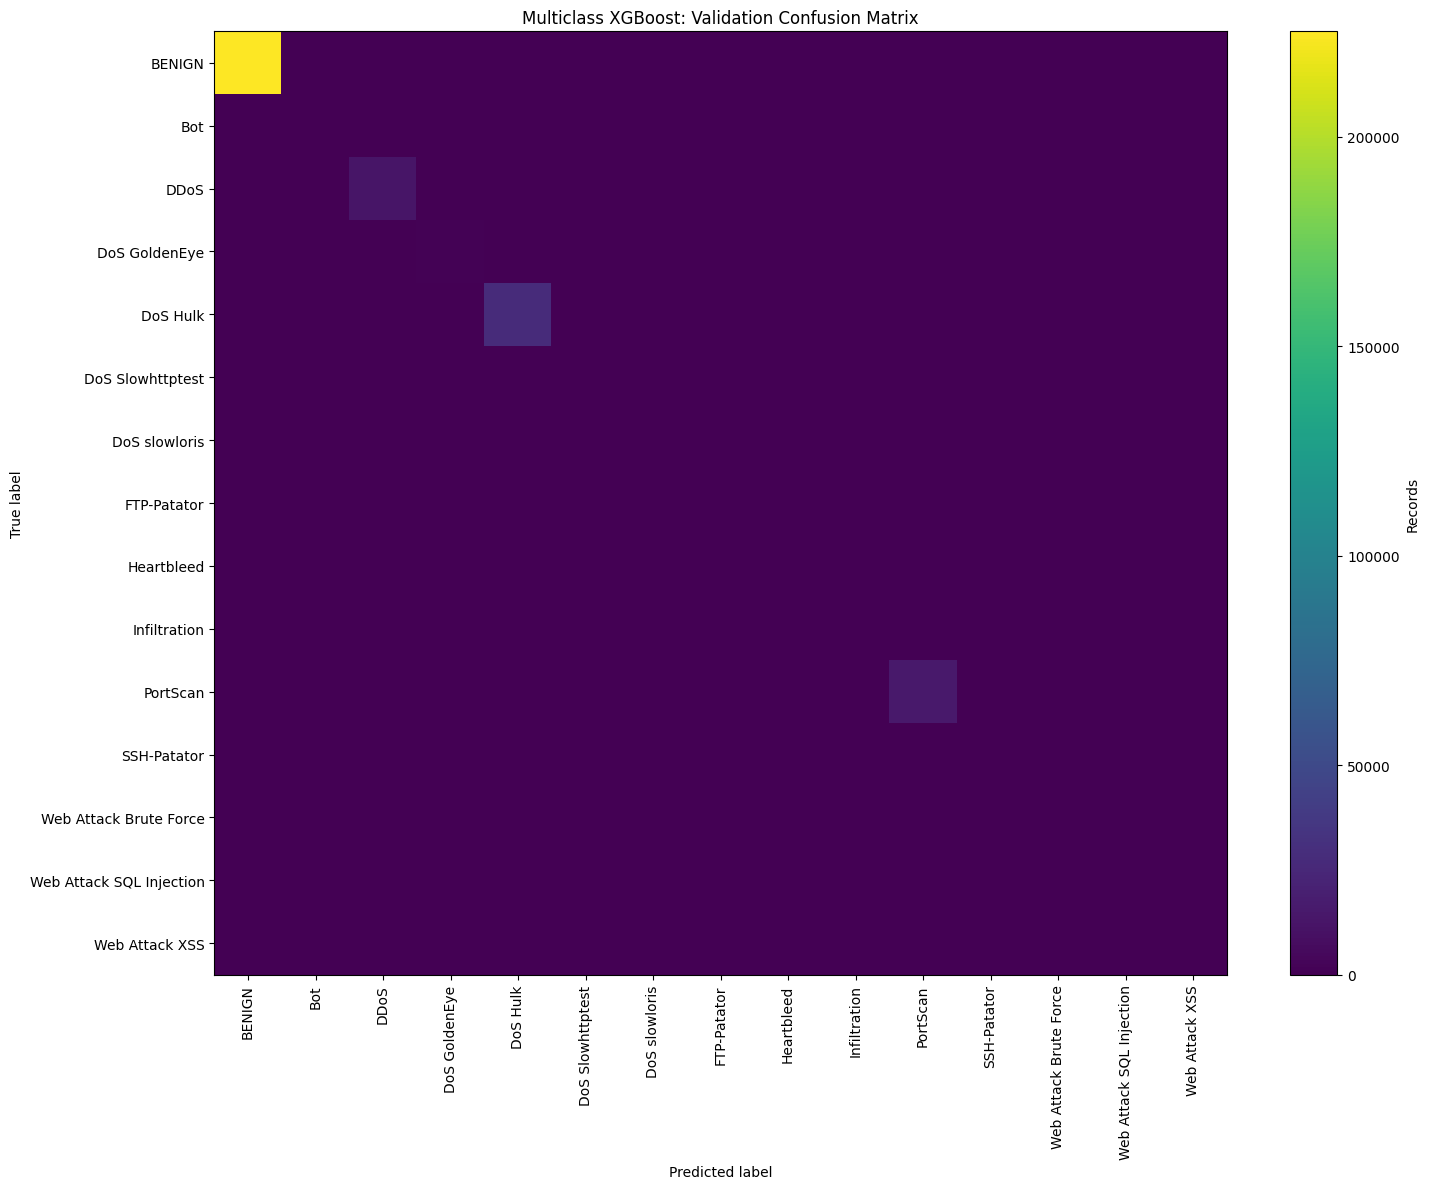

In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

# Predict the class with the highest probability.
val_probabilities = multiclass_model.predict_proba(X_val_imputed)
y_val_pred = np.argmax(val_probabilities, axis=1)

assert val_probabilities.shape == (len(y_val), len(CLASS_NAMES))
assert np.isfinite(val_probabilities).all()

accuracy = accuracy_score(y_val, y_val_pred)
balanced_acc = balanced_accuracy_score(y_val, y_val_pred)

precision, recall, f1, support = precision_recall_fscore_support(
    y_val,
    y_val_pred,
    labels=np.arange(len(CLASS_NAMES)),
    zero_division=0,
)

print("MULTICLASS VALIDATION RESULTS")
print("=" * 60)
print(f"Accuracy:          {accuracy:.6f}")
print(f"Balanced accuracy: {balanced_acc:.6f}")
print(f"Macro precision:   {precision.mean():.6f}")
print(f"Macro recall:      {recall.mean():.6f}")
print(f"Macro F1:          {f1.mean():.6f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_val_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=5,
))

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=np.arange(len(CLASS_NAMES)),
)

fig, ax = plt.subplots(figsize=(15, 12))
im = ax.imshow(cm, interpolation="nearest", aspect="auto")
ax.set_title("Multiclass XGBoost: Validation Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(np.arange(len(CLASS_NAMES)))
ax.set_yticks(np.arange(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticklabels(CLASS_NAMES)
fig.colorbar(im, ax=ax, label="Records")
fig.tight_layout()
plt.show()


In [ ]:

import joblib
import json
from pathlib import Path

MODEL_DIR = PROJECT_ROOT / "models/multiclass"
METRICS_DIR = PROJECT_ROOT / "outputs/metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE_PATH = MODEL_DIR / "xgboost_multiclass_bundle.joblib"
MODEL_JSON_PATH = MODEL_DIR / "xgboost_multiclass_model.json"
MAPPING_PATH = MODEL_DIR / "multiclass_label_mapping.json"

# Save the model separately in XGBoost's native format.
multiclass_model.save_model(str(MODEL_JSON_PATH))

# Save everything required for consistent inference.
bundle = {
    "model": multiclass_model,
    "imputer": imputer,
    "feature_columns": FEATURE_COLUMNS,
    "class_names": CLASS_NAMES,
    "class_to_id": CLASS_TO_ID,
    "id_to_class": ID_TO_CLASS,
    "best_iteration": int(multiclass_model.best_iteration),
    "num_classes": len(CLASS_NAMES),
    "model_type": "XGBoost multiclass",
}

joblib.dump(bundle, BUNDLE_PATH)

with open(MAPPING_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {
            "class_to_id": CLASS_TO_ID,
            "id_to_class": ID_TO_CLASS,
        },
        f,
        indent=2,
        ensure_ascii=False,
    )

print("Multiclass model saved:", BUNDLE_PATH)
print("Native XGBoost model saved:", MODEL_JSON_PATH)
print("Label mapping saved:", MAPPING_PATH)

# Verify that the saved bundle can be reloaded.
loaded_bundle = joblib.load(BUNDLE_PATH)

assert loaded_bundle["num_classes"] == 15
assert len(loaded_bundle["feature_columns"]) == 78
assert loaded_bundle["class_names"] == CLASS_NAMES
assert hasattr(loaded_bundle["model"], "predict_proba")

print("Bundle reload check: PASSED")


Multiclass model saved: /content/drive/MyDrive/H-IDS/models/multiclass/xgboost_multiclass_bundle.joblib
Native XGBoost model saved: /content/drive/MyDrive/H-IDS/models/multiclass/xgboost_multiclass_model.json
Label mapping saved: /content/drive/MyDrive/H-IDS/models/multiclass/multiclass_label_mapping.json
Bundle reload check: PASSED


In [2]:
# Check whether preprocessing variables exist in memory

required_variables = [
    "X_train_imputed",
    "X_val_imputed",
    "y_train",
    "y_val",
    "imputer",
    "FEATURE_COLUMNS",
    "CLASS_NAMES",
    "params",
    "PROJECT_ROOT",
]

for name in required_variables:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

X_train_imputed: MISSING
X_val_imputed: MISSING
y_train: MISSING
y_val: MISSING
imputer: MISSING
FEATURE_COLUMNS: AVAILABLE
CLASS_NAMES: MISSING
params: MISSING
PROJECT_ROOT: AVAILABLE


In [3]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

paths_to_check = [
    PROJECT_ROOT / "data/processed",
    PROJECT_ROOT / "data/splits",
    PROJECT_ROOT / "models/binary/xgboost_binary_bundle.joblib",
    PROJECT_ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib",
]

for path in paths_to_check:
    print(f"{'EXISTS' if path.exists() else 'MISSING'}: {path}")

print("\nFiles in data/splits:")
split_dir = PROJECT_ROOT / "data/splits"

if split_dir.exists():
    for file in split_dir.iterdir():
        print(file.name)

EXISTS: /content/drive/MyDrive/H-IDS/data/processed
EXISTS: /content/drive/MyDrive/H-IDS/data/splits
EXISTS: /content/drive/MyDrive/H-IDS/models/binary/xgboost_binary_bundle.joblib
EXISTS: /content/drive/MyDrive/H-IDS/models/multiclass/xgboost_multiclass_bundle.joblib

Files in data/splits:
duplicate_aware_split.parquet
duplicate_aware_split_summary.json
train.parquet
validation.parquet
test.parquet


In [4]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

train_df = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_df = pd.read_parquet(SPLIT_DIR / "validation.parquet")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

print("\nFirst 5 training rows:")
display(train_df.head())

Train shape: (1990486, 82)
Validation shape: (285201, 82)

Train columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Cou

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,label_raw,label,source_file,source_row
0,54865.0,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,0
1,55054.0,109.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,1
2,55055.0,52.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2
3,54871.0,1022.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,5
4,54925.0,4.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,6


In [5]:
BINARY_BUNDLE_PATH = (
    PROJECT_ROOT / "models" / "binary" /
    "xgboost_binary_bundle.joblib"
)

MULTICLASS_BUNDLE_PATH = (
    PROJECT_ROOT / "models" / "multiclass" /
    "xgboost_multiclass_bundle.joblib"
)

binary_bundle = joblib.load(BINARY_BUNDLE_PATH)
multiclass_bundle = joblib.load(MULTICLASS_BUNDLE_PATH)

print("Binary bundle type:", type(binary_bundle))
print("Multiclass bundle type:", type(multiclass_bundle))

if isinstance(multiclass_bundle, dict):
    print("\nMulticlass bundle keys:")
    print(list(multiclass_bundle.keys()))

Binary bundle type: <class 'dict'>
Multiclass bundle type: <class 'dict'>

Multiclass bundle keys:
['model', 'imputer', 'feature_columns', 'class_names', 'class_to_id', 'id_to_class', 'best_iteration', 'num_classes', 'model_type']


In [6]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

bundle_path = (
    PROJECT_ROOT
    / "models"
    / "multiclass"
    / "xgboost_multiclass_bundle.joblib"
)

multiclass_bundle = joblib.load(bundle_path)

model = multiclass_bundle["model"]
imputer = multiclass_bundle["imputer"]
FEATURE_COLUMNS = multiclass_bundle["feature_columns"]
CLASS_NAMES = multiclass_bundle["class_names"]

print("Model loaded:", model is not None)
print("Imputer loaded:", imputer is not None)
print("Feature count:", len(FEATURE_COLUMNS))
print("Class count:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)

Model loaded: True
Imputer loaded: True
Feature count: 78
Class count: 15
Classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack Brute Force', 'Web Attack SQL Injection', 'Web Attack XSS']


In [7]:
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

train_df = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_df = pd.read_parquet(SPLIT_DIR / "validation.parquet")

# Separate multiclass target labels
y_train = train_df["label"].copy()
y_val = val_df["label"].copy()

# Select only the model's original 78 features, in the saved order
X_train = train_df[FEATURE_COLUMNS].copy()
X_val = val_df[FEATURE_COLUMNS].copy()

# Apply the previously fitted imputer
X_train_imputed = imputer.transform(X_train)
X_val_imputed = imputer.transform(X_val)

print("Training features:", X_train_imputed.shape)
print("Validation features:", X_val_imputed.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


Training features: (1990486, 78)
Validation features: (285201, 78)
Training labels: (1990486,)
Validation labels: (285201,)


In [8]:
assert X_train_imputed.shape == (len(train_df), 78)
assert X_val_imputed.shape == (len(val_df), 78)
assert len(y_train) == X_train_imputed.shape[0]
assert len(y_val) == X_val_imputed.shape[0]
assert len(FEATURE_COLUMNS) == 78

assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()

print("PASS: preprocessing data restored successfully.")
print("PASS: training and validation feature counts match.")
print("PASS: imputed features contain no NaN or infinite values.")
print("Ready for the next multiclass experiment.")

PASS: preprocessing data restored successfully.
PASS: training and validation feature counts match.
PASS: imputed features contain no NaN or infinite values.
Ready for the next multiclass experiment.


In [9]:
from collections import Counter
import pandas as pd

class_counts = y_train.value_counts()

class_summary = pd.DataFrame({
    "class": class_counts.index,
    "training_samples": class_counts.values,
})

class_summary["percentage"] = (
    class_summary["training_samples"]
    / len(y_train) * 100
)

display(
    class_summary.sort_values("training_samples")
    .reset_index(drop=True)
)

,class,training_samples,percentage
0,Heartbleed,9,0.000452
1,Web Attack SQL Injection,15,0.000754
2,Infiltration,24,0.001206
3,Web Attack XSS,466,0.023411
4,Web Attack Brute Force,1056,0.053052
5,Bot,1407,0.070686
6,DoS Slowhttptest,3892,0.195530
7,DoS slowloris,4136,0.207788
8,SSH-Patator,4246,0.213315
9,FTP-Patator,5904,0.296611


In [10]:
print("Model classes:")
print(CLASS_NAMES)

print("\nTraining label examples:")
print(y_train.head(10).tolist())

print("\nLabel data type:", y_train.dtype)

Model classes:
['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack Brute Force', 'Web Attack SQL Injection', 'Web Attack XSS']

Training label examples:
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']

Label data type: object


In [11]:
import numpy as np
import pandas as pd

CLASS_NAMES = list(CLASS_NAMES)
class_to_id = {name: idx for idx, name in enumerate(CLASS_NAMES)}

unknown_train = set(y_train.unique()) - set(CLASS_NAMES)
unknown_val = set(y_val.unique()) - set(CLASS_NAMES)

assert not unknown_train, f"Unknown training labels: {unknown_train}"
assert not unknown_val, f"Unknown validation labels: {unknown_val}"

y_train_encoded = y_train.map(class_to_id).to_numpy(dtype=np.int32)
y_val_encoded = y_val.map(class_to_id).to_numpy(dtype=np.int32)

print("Encoded training labels:", y_train_encoded.shape)
print("Encoded validation labels:", y_val_encoded.shape)
print("Class mapping:")
print(class_to_id)

assert set(np.unique(y_train_encoded)) == set(range(len(CLASS_NAMES)))
print("PASS: label encoding matches the saved class order.")

Encoded training labels: (1990486,)
Encoded validation labels: (285201,)
Class mapping:
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Heartbleed': 8, 'Infiltration': 9, 'PortScan': 10, 'SSH-Patator': 11, 'Web Attack Brute Force': 12, 'Web Attack SQL Injection': 13, 'Web Attack XSS': 14}
PASS: label encoding matches the saved class order.


In [12]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.arange(len(CLASS_NAMES))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

# Square-root weighting reduces the extreme effect of rare classes
sqrt_weights = np.sqrt(weights)

# Normalize weights so their average across training examples is 1
sample_weights = sqrt_weights[y_train_encoded]
sample_weights = sample_weights / sample_weights.mean()

weight_table = pd.DataFrame({
    "class_id": classes,
    "class_name": CLASS_NAMES,
    "training_samples": [
        int(np.sum(y_train_encoded == c)) for c in classes
    ],
    "class_weight": sqrt_weights
})

display(weight_table.sort_values("training_samples"))
print("Sample weights:", sample_weights.shape)
print("Mean sample weight:", sample_weights.mean())

,class_id,class_name,training_samples,class_weight
8,8,Heartbleed,9,121.426277
13,13,Web Attack SQL Injection,15,94.056390
9,9,Infiltration,24,74.358105
14,14,Web Attack XSS,466,16.874891
12,12,Web Attack Brute Force,1056,11.209906
1,1,Bot,1407,9.711513
5,5,DoS Slowhttptest,3892,5.839122
6,6,DoS slowloris,4136,5.664266
11,11,SSH-Patator,4246,5.590414
7,7,FTP-Patator,5904,4.740900


Sample weights: (1990486,)
Mean sample weight: 1.0000000000000013


In [13]:
print("Saved model type:", type(model).__name__)

if hasattr(model, "get_params"):
    saved_params = model.get_params()
    for key in [
        "objective",
        "num_class",
        "n_estimators",
        "learning_rate",
        "max_depth",
        "min_child_weight",
        "subsample",
        "colsample_bytree",
        "reg_lambda",
        "tree_method",
        "device",
        "random_state"
    ]:
        print(f"{key}: {saved_params.get(key)}")

Saved model type: XGBClassifier
objective: multi:softprob
num_class: 15
n_estimators: 300
learning_rate: 0.08
max_depth: 8
min_child_weight: 5
subsample: 0.8
colsample_bytree: 0.8
reg_lambda: 2.0
tree_method: hist
device: cuda
random_state: 42


In [14]:
from sklearn.base import clone
from pathlib import Path
import numpy as np
import time

# Clone the existing model configuration without modifying the baseline
weighted_model = clone(model)

# Configure early stopping
weighted_model.set_params(early_stopping_rounds=20)

# Keep the sample weights in a compact format
sample_weights_fit = sample_weights.astype(np.float32, copy=False)

print("Starting class-weighted multiclass training...")
print("Training rows:", X_train_imputed.shape[0])
print("Features:", X_train_imputed.shape[1])
print("Classes:", len(CLASS_NAMES))
print("Mean sample weight:", float(sample_weights_fit.mean()))

start_time = time.time()

weighted_model.fit(
    X_train_imputed,
    y_train_encoded,
    sample_weight=sample_weights_fit,
    eval_set=[(X_val_imputed, y_val_encoded)],
    verbose=50
)

training_seconds = time.time() - start_time

print(f"\nTraining completed in {training_seconds / 60:.2f} minutes.")

if hasattr(weighted_model, "best_iteration"):
    print("Best iteration:", weighted_model.best_iteration)

Starting class-weighted multiclass training...
Training rows: 1990486
Features: 78
Classes: 15
Mean sample weight: 0.9999996423721313
[0]	validation_0-mlogloss:0.94715
[50]	validation_0-mlogloss:0.02228
[100]	validation_0-mlogloss:0.00533
[150]	validation_0-mlogloss:0.00463
[200]	validation_0-mlogloss:0.00454
[236]	validation_0-mlogloss:0.00454

Training completed in 2.50 minutes.
Best iteration: 216


In [15]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Predictions from the existing baseline
baseline_val_pred = model.predict(X_val_imputed).astype(int)

# Predictions from the weighted candidate
weighted_val_pred = weighted_model.predict(X_val_imputed).astype(int)

def evaluate_multiclass(y_true, y_pred, name):
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }
    return metrics

comparison = pd.DataFrame([
    evaluate_multiclass(
        y_val_encoded, baseline_val_pred, "Baseline"
    ),
    evaluate_multiclass(
        y_val_encoded, weighted_val_pred, "Class-weighted candidate"
    )
])

display(comparison)

print("\nCLASS-WEIGHTED CANDIDATE: PER-CLASS RESULTS")
print(classification_report(
    y_val_encoded,
    weighted_val_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [19:46:59] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,Baseline,0.998962,0.846939,0.87251,0.998945
1,Class-weighted candidate,0.998797,0.858846,0.86523,0.998836



CLASS-WEIGHTED CANDIDATE: PER-CLASS RESULTS
                          precision    recall  f1-score   support

                  BENIGN     1.0000    0.9989    0.9994    225274
                     Bot     0.6502    0.9787    0.7813       188
                    DDoS     0.9998    1.0000    0.9999     12886
           DoS GoldenEye     0.9906    0.9991    0.9948      1059
                DoS Hulk     0.9987    0.9997    0.9992     27448
        DoS Slowhttptest     0.9873    0.9909    0.9891       549
           DoS slowloris     0.9910    0.9982    0.9946       554
             FTP-Patator     1.0000    1.0000    1.0000       716
              Heartbleed     0.0000    0.0000    0.0000         0
            Infiltration     1.0000    0.6667    0.8000         3
                PortScan     0.9936    0.9997    0.9967     15627
             SSH-Patator     1.0000    0.9986    0.9993       693
  Web Attack Brute Force     0.7622    0.7267    0.7440       150
Web Attack SQL Injection     1

In [16]:
import json
import joblib
from pathlib import Path
from sklearn.metrics import f1_score, balanced_accuracy_score

MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

candidate_path = (
    MODEL_DIR / "xgboost_multiclass_weighted_candidate.joblib"
)

weighted_val_metrics = {
    "accuracy": float(
        (weighted_val_pred == y_val_encoded).mean()
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val_encoded, weighted_val_pred)
    ),
    "macro_f1": float(
        f1_score(
            y_val_encoded, weighted_val_pred,
            average="macro", zero_division=0
        )
    ),
    "weighted_f1": float(
        f1_score(
            y_val_encoded, weighted_val_pred,
            average="weighted", zero_division=0
        )
    ),
}

candidate_bundle = {
    "model": weighted_model,
    "imputer": imputer,
    "feature_columns": FEATURE_COLUMNS,
    "class_names": CLASS_NAMES,
    "class_to_id": class_to_id,
    "experiment": "sqrt_inverse_frequency_sample_weighting",
    "validation_metrics": weighted_val_metrics,
    "best_iteration": int(weighted_model.best_iteration),
}

joblib.dump(candidate_bundle, candidate_path)

metrics_path = METRICS_DIR / "weighted_candidate_validation_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(weighted_val_metrics, f, indent=2)

print("Candidate saved:", candidate_path)
print("Metrics saved:", metrics_path)
print(json.dumps(weighted_val_metrics, indent=2))

Candidate saved: /content/drive/MyDrive/H-IDS/models/multiclass/xgboost_multiclass_weighted_candidate.joblib
Metrics saved: /content/drive/MyDrive/H-IDS/outputs/metrics/weighted_candidate_validation_metrics.json
{
  "accuracy": 0.9987973394202685,
  "balanced_accuracy": 0.8588455965134042,
  "macro_f1": 0.8652301852007617,
  "weighted_f1": 0.9988362505240719
}


In [18]:

from sklearn.metrics import precision_recall_fscore_support
import numpy as np
import pandas as pd

def class_metrics(y_true, y_pred, prefix):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES)),
        zero_division=0
    )

    return pd.DataFrame({
        "class_id": np.arange(len(CLASS_NAMES)),
        "class_name": CLASS_NAMES,
        f"{prefix}_precision": precision,
        f"{prefix}_recall": recall,
        f"{prefix}_f1": f1,
        f"{prefix}_support": support,
    })

baseline_report = class_metrics(
    y_val_encoded, baseline_val_pred, "baseline"
)

weighted_report = class_metrics(
    y_val_encoded, weighted_val_pred, "weighted"
)

# Merge using only columns that exist in both reports
class_comparison = baseline_report.merge(
    weighted_report,
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one"
)

class_comparison["recall_change"] = (
    class_comparison["weighted_recall"]
    - class_comparison["baseline_recall"]
)

class_comparison["f1_change"] = (
    class_comparison["weighted_f1"]
    - class_comparison["baseline_f1"]
)

print("Class-wise comparison: negative F1 changes indicate declines.")
display(
    class_comparison.sort_values("f1_change").reset_index(drop=True)
)


Class-wise comparison: negative F1 changes indicate declines.


,class_id,class_name,baseline_precision,baseline_recall,baseline_f1,baseline_support,weighted_precision,weighted_recall,weighted_f1,weighted_support,recall_change,f1_change
0,12,Web Attack Brute Force,0.788462,0.820000,0.803922,150,0.762238,0.726667,0.744027,150,-0.093333,-0.059894
1,14,Web Attack XSS,0.372093,0.313725,0.340426,51,0.298246,0.333333,0.314815,51,0.019608,-0.025611
2,1,Bot,0.858896,0.744681,0.797721,188,0.650177,0.978723,0.781316,188,0.234043,-0.016404
3,3,DoS GoldenEye,0.995283,0.996223,0.995753,1059,0.990637,0.999056,0.994828,1059,0.002833,-0.000924
4,11,SSH-Patator,1.000000,1.000000,1.000000,693,1.000000,0.998557,0.999278,693,-0.001443,-0.000722
5,4,DoS Hulk,0.998799,0.999818,0.999308,27448,0.998690,0.999745,0.999217,27448,-0.000073,-0.000091
6,0,BENIGN,0.999720,0.999285,0.999503,225274,0.999956,0.998926,0.999440,225274,-0.000360,-0.000062
7,2,DDoS,0.999922,1.000000,0.999961,12886,0.999845,1.000000,0.999922,12886,0.000000,-0.000039
8,10,PortScan,0.993640,0.999744,0.996683,15627,0.993640,0.999744,0.996683,15627,0.000000,0.000000
9,9,Infiltration,1.000000,0.666667,0.800000,3,1.000000,0.666667,0.800000,3,0.000000,0.000000


In [19]:
# Calculate inverse-frequency class weights from training data only
counts = np.bincount(y_train_encoded, minlength=len(CLASS_NAMES))

balanced_weights = (
    len(y_train_encoded) / (len(CLASS_NAMES) * counts)
)

# Milder weighting: exponent 0.25 instead of 0.50
mild_class_weights = balanced_weights ** 0.25

# Convert class weights to per-record sample weights
mild_sample_weights = mild_class_weights[y_train_encoded]

# Normalize average sample weight to 1
mild_sample_weights = (
    mild_sample_weights / mild_sample_weights.mean()
).astype(np.float32)

mild_weight_table = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "training_samples": counts,
    "previous_sqrt_weight": sqrt_weights,
    "mild_weight": mild_class_weights
})

display(mild_weight_table.sort_values("training_samples"))
print("Mean sample weight:", mild_sample_weights.mean())

,class_name,training_samples,previous_sqrt_weight,mild_weight
8,Heartbleed,9,121.426277,11.019359
13,Web Attack SQL Injection,15,94.056390,9.698267
9,Infiltration,24,74.358105,8.623115
14,Web Attack XSS,466,16.874891,4.107906
12,Web Attack Brute Force,1056,11.209906,3.348120
1,Bot,1407,9.711513,3.116330
5,DoS Slowhttptest,3892,5.839122,2.416427
6,DoS slowloris,4136,5.664266,2.379972
11,SSH-Patator,4246,5.590414,2.364406
7,FTP-Patator,5904,4.740900,2.177361


Mean sample weight: 0.99999934


In [20]:
from sklearn.base import clone
import time

mild_model = clone(model)
mild_model.set_params(early_stopping_rounds=20)

print("Training mildly weighted candidate...")
start_time = time.time()

mild_model.fit(
    X_train_imputed,
    y_train_encoded,
    sample_weight=mild_sample_weights,
    eval_set=[(X_val_imputed, y_val_encoded)],
    verbose=50
)

print(
    f"Training time: {(time.time() - start_time) / 60:.2f} minutes"
)
print("Best iteration:", mild_model.best_iteration)

Training mildly weighted candidate...
[0]	validation_0-mlogloss:0.68596
[50]	validation_0-mlogloss:0.01458
[100]	validation_0-mlogloss:0.00423
[150]	validation_0-mlogloss:0.00376
[200]	validation_0-mlogloss:0.00371
[222]	validation_0-mlogloss:0.00371
Training time: 2.33 minutes
Best iteration: 202


In [21]:
mild_val_pred = mild_model.predict(X_val_imputed).astype(int)

comparison_three = pd.DataFrame([
    evaluate_multiclass(
        y_val_encoded, baseline_val_pred, "Baseline"
    ),
    evaluate_multiclass(
        y_val_encoded, weighted_val_pred, "Sqrt-weighted"
    ),
    evaluate_multiclass(
        y_val_encoded, mild_val_pred, "Mild-weighted"
    )
])

display(comparison_three)

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,Baseline,0.998962,0.846939,0.872510,0.998945
1,Sqrt-weighted,0.998797,0.858846,0.865230,0.998836
2,Mild-weighted,0.998832,0.855504,0.866286,0.998861


In [22]:
mild_report = class_metrics(
    y_val_encoded, mild_val_pred, "mild"
)

mild_comparison = baseline_report.merge(
    mild_report,
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one"
)

mild_comparison["mild_f1_change"] = (
    mild_comparison["mild_f1"]
    - mild_comparison["baseline_f1"]
)

display(
    mild_comparison.sort_values("mild_f1_change")
    .reset_index(drop=True)
)

,class_id,class_name,baseline_precision,baseline_recall,baseline_f1,baseline_support,mild_precision,mild_recall,mild_f1,mild_support,mild_f1_change
0,12,Web Attack Brute Force,0.788462,0.820000,0.803922,150,0.776224,0.740000,0.757679,150,-4.624239e-02
1,14,Web Attack XSS,0.372093,0.313725,0.340426,51,0.303571,0.333333,0.317757,51,-2.266852e-02
2,1,Bot,0.858896,0.744681,0.797721,188,0.670543,0.920213,0.775785,188,-2.193604e-02
3,11,SSH-Patator,1.000000,1.000000,1.000000,693,1.000000,0.998557,0.999278,693,-7.220217e-04
4,0,BENIGN,0.999720,0.999285,0.999503,225274,0.999898,0.998997,0.999447,225274,-5.562894e-05
5,4,DoS Hulk,0.998799,0.999818,0.999308,27448,0.998654,0.999891,0.999272,27448,-3.633440e-05
6,7,FTP-Patator,1.000000,1.000000,1.000000,716,1.000000,1.000000,1.000000,716,0.000000e+00
7,2,DDoS,0.999922,1.000000,0.999961,12886,0.999922,1.000000,0.999961,12886,0.000000e+00
8,13,Web Attack SQL Injection,1.000000,0.333333,0.500000,3,1.000000,0.333333,0.500000,3,0.000000e+00
9,9,Infiltration,1.000000,0.666667,0.800000,3,1.000000,0.666667,0.800000,3,0.000000e+00


In [23]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

cm_baseline = confusion_matrix(
    y_val_encoded,
    baseline_val_pred,
    labels=np.arange(len(CLASS_NAMES))
)

confusion_pairs = []

for actual_id in range(len(CLASS_NAMES)):
    for predicted_id in range(len(CLASS_NAMES)):
        if actual_id == predicted_id:
            continue

        count = int(cm_baseline[actual_id, predicted_id])

        if count > 0:
            confusion_pairs.append({
                "actual_class": CLASS_NAMES[actual_id],
                "predicted_class": CLASS_NAMES[predicted_id],
                "misclassified_records": count
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)

display(
    confusion_pairs_df
    .sort_values("misclassified_records", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

,actual_class,predicted_class,misclassified_records
0,BENIGN,PortScan,100
1,Bot,BENIGN,48
2,Web Attack XSS,Web Attack Brute Force,32
3,BENIGN,DoS Hulk,28
4,Web Attack Brute Force,Web Attack XSS,27
5,BENIGN,Bot,23
6,BENIGN,DoS Slowhttptest,7
7,DoS Hulk,BENIGN,3
8,PortScan,DoS Hulk,3
9,Web Attack XSS,BENIGN,3


In [24]:
import pandas as pd
import numpy as np

# Class IDs from the saved class mapping
BRUTE_ID = class_to_id["Web Attack Brute Force"]
XSS_ID = class_to_id["Web Attack XSS"]

# Locate validation records involving either class
web_mask = (
    (y_val_encoded == BRUTE_ID) |
    (y_val_encoded == XSS_ID)
)

# Compare actual labels and baseline predictions
web_analysis = pd.DataFrame({
    "actual_id": y_val_encoded[web_mask],
    "predicted_id": baseline_val_pred[web_mask]
})

web_analysis["actual_class"] = web_analysis["actual_id"].map(
    {i: name for i, name in enumerate(CLASS_NAMES)}
)

web_analysis["predicted_class"] = web_analysis["predicted_id"].map(
    {i: name for i, name in enumerate(CLASS_NAMES)}
)

display(
    pd.crosstab(
        web_analysis["actual_class"],
        web_analysis["predicted_class"]
    )
)

predicted_class,BENIGN,Web Attack Brute Force,Web Attack XSS
actual_class,,,
Web Attack Brute Force,0,123,27
Web Attack XSS,3,32,16


In [25]:
# Original feature values, preserving the saved feature order
web_features = X_val.loc[web_mask, FEATURE_COLUMNS].copy()

web_features["actual_class"] = (
    y_val.loc[web_mask].to_numpy()
)

print("Web-attack validation records:", len(web_features))

feature_summary = web_features.groupby("actual_class")[
    FEATURE_COLUMNS
].median().T

display(feature_summary)

Web-attack validation records: 201


actual_class,Web Attack Brute Force,Web Attack XSS
Destination Port,80.0,80.0
Flow Duration,5453312.0,5389098.0
Total Fwd Packets,3.0,3.0
Total Backward Packets,1.0,1.0
Total Length of Fwd Packets,0.0,0.0
...,...,...
Active Min,0.0,0.0
Idle Mean,0.0,0.0
Idle Std,0.0,0.0
Idle Max,0.0,0.0


In [26]:
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

brute_mask = y_val.eq("Web Attack Brute Force").to_numpy()
xss_mask = y_val.eq("Web Attack XSS").to_numpy()

brute_df = X_val.loc[brute_mask, FEATURE_COLUMNS]
xss_df = X_val.loc[xss_mask, FEATURE_COLUMNS]

results = []

for feature in FEATURE_COLUMNS:
    a = brute_df[feature].replace([np.inf, -np.inf], np.nan).dropna()
    b = xss_df[feature].replace([np.inf, -np.inf], np.nan).dropna()

    if len(a) == 0 or len(b) == 0:
        continue

    test = ks_2samp(a, b)

    results.append({
        "feature": feature,
        "brute_median": a.median(),
        "xss_median": b.median(),
        "brute_nonzero_pct": (a != 0).mean() * 100,
        "xss_nonzero_pct": (b != 0).mean() * 100,
        "ks_statistic": test.statistic,
        "ks_pvalue": test.pvalue,
    })

distribution_report = pd.DataFrame(results).sort_values(
    "ks_statistic", ascending=False
)

display(distribution_report.head(20))

,feature,brute_median,xss_median,brute_nonzero_pct,xss_nonzero_pct,ks_statistic,ks_pvalue
37,Bwd Packets/s,1.868227e-01,1.852924e-01,100.000000,94.117647,0.169020,0.199003
19,Flow IAT Min,1.240000e+02,1.260000e+02,100.000000,100.000000,0.164314,0.225048
1,Flow Duration,5.453312e+06,5.389098e+06,100.000000,100.000000,0.145490,0.355040
36,Fwd Packets/s,5.564508e-01,5.591257e-01,100.000000,100.000000,0.138039,0.417600
20,Fwd IAT Total,5.411230e+06,5.389098e+06,90.000000,98.039216,0.118824,0.605113
18,Flow IAT Max,5.351790e+06,5.364645e+06,100.000000,100.000000,0.111373,0.681372
16,Flow IAT Mean,1.784228e+06,1.788507e+06,100.000000,100.000000,0.111373,0.681372
15,Flow Packets/s,7.472906e-01,7.455009e-01,100.000000,100.000000,0.111373,0.681372
17,Flow IAT Std,3.089600e+06,3.097027e+06,90.000000,92.156863,0.111373,0.681372
23,Fwd IAT Max,5.351790e+06,5.364645e+06,90.000000,98.039216,0.111373,0.681372


In [27]:
web_errors_mask = (
    ((y_val == "Web Attack XSS") &
     (pd.Series(baseline_val_pred, index=y_val.index)
      .map(dict(enumerate(CLASS_NAMES))) == "Web Attack Brute Force"))
    |
    ((y_val == "Web Attack Brute Force") &
     (pd.Series(baseline_val_pred, index=y_val.index)
      .map(dict(enumerate(CLASS_NAMES))) == "Web Attack XSS"))
)

web_errors = X_val.loc[web_errors_mask, FEATURE_COLUMNS].copy()
web_errors["actual_class"] = y_val.loc[web_errors_mask]
web_errors["predicted_class"] = pd.Series(
    baseline_val_pred, index=y_val.index
).loc[web_errors_mask].map(dict(enumerate(CLASS_NAMES)))

print("Cross-confused records:", len(web_errors))
display(web_errors.head(10))

Cross-confused records: 59


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,actual_class,predicted_class
152859,80.0,5294438.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
152890,80.0,5457414.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
152895,80.0,5406316.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
152988,80.0,5155697.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153136,80.0,5361343.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153422,80.0,5424045.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153430,80.0,5523862.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153498,80.0,5327833.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153773,80.0,5610645.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS
153808,80.0,5213705.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Web Attack Brute Force,Web Attack XSS


In [28]:
# Inspect source metadata for the two web-attack classes
web_rows = val_df.loc[
    val_df["label"].isin([
        "Web Attack Brute Force",
        "Web Attack XSS"
    ]),
    ["label", "source_file", "source_row"]
].copy()

print("Records per source file and class:")
display(pd.crosstab(
    web_rows["source_file"],
    web_rows["label"]
))

# Attach baseline predictions to validation records
predicted_labels = pd.Series(
    [CLASS_NAMES[i] for i in baseline_val_pred],
    index=val_df.index
)

web_rows["predicted_class"] = predicted_labels.loc[web_rows.index]

print("\nCross-confusion counts by source file:")
cross_errors = web_rows[
    (
        (web_rows["label"] == "Web Attack Brute Force") &
        (web_rows["predicted_class"] == "Web Attack XSS")
    ) |
    (
        (web_rows["label"] == "Web Attack XSS") &
        (web_rows["predicted_class"] == "Web Attack Brute Force")
    )
]

display(pd.crosstab(
    cross_errors["source_file"],
    cross_errors["label"]
))

Records per source file and class:


label,Web Attack Brute Force,Web Attack XSS
source_file,,
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,150,51



Cross-confusion counts by source file:


label,Web Attack Brute Force,Web Attack XSS
source_file,,
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,27,32


In [29]:
web_classes = ["Web Attack Brute Force", "Web Attack XSS"]

print("TRAINING COUNTS BY SOURCE")
display(pd.crosstab(
    train_df.loc[train_df["label"].isin(web_classes), "source_file"],
    train_df.loc[train_df["label"].isin(web_classes), "label"]
))

print("\nVALIDATION COUNTS BY SOURCE")
display(pd.crosstab(
    val_df.loc[val_df["label"].isin(web_classes), "source_file"],
    val_df.loc[val_df["label"].isin(web_classes), "label"]
))

TRAINING COUNTS BY SOURCE


label,Web Attack Brute Force,Web Attack XSS
source_file,,
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,1056,466



VALIDATION COUNTS BY SOURCE


label,Web Attack Brute Force,Web Attack XSS
source_file,,
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,150,51


In [30]:
# Count identical feature vectors across the two web-attack classes.
web_train = train_df.loc[
    train_df["label"].isin(web_classes),
    FEATURE_COLUMNS + ["label"]
].copy()

web_val = val_df.loc[
    val_df["label"].isin(web_classes),
    FEATURE_COLUMNS + ["label"]
].copy()

train_vectors = web_train.groupby(FEATURE_COLUMNS, dropna=False)["label"].agg(
    labels="nunique",
    records="size"
)

print("Training feature-vector groups:", len(train_vectors))
print("Groups with multiple labels:", int((train_vectors["labels"] > 1).sum()))
print("Groups repeated within training:", int((train_vectors["records"] > 1).sum()))

Training feature-vector groups: 1494
Groups with multiple labels: 0
Groups repeated within training: 17


In [31]:
import pandas as pd

web_classes = ["Web Attack Brute Force", "Web Attack XSS"]

train_web = train_df.loc[
    train_df["label"].isin(web_classes),
    FEATURE_COLUMNS
].copy()

val_web = val_df.loc[
    val_df["label"].isin(web_classes),
    FEATURE_COLUMNS
].copy()

# Convert feature rows to hashes for an efficient exact-match audit
train_hashes = pd.util.hash_pandas_object(
    train_web, index=False
)

val_hashes = pd.util.hash_pandas_object(
    val_web, index=False
)

train_hash_set = set(train_hashes)
overlap_mask = val_hashes.isin(train_hash_set)

print("Training web-attack records:", len(train_web))
print("Validation web-attack records:", len(val_web))
print("Validation records with matching training feature hashes:",
      int(overlap_mask.sum()))
print("Percentage of validation records with a matching hash:",
      round(overlap_mask.mean() * 100, 3), "%")

Training web-attack records: 1522
Validation web-attack records: 201
Validation records with matching training feature hashes: 0
Percentage of validation records with a matching hash: 0.0 %


In [32]:
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

web_classes = ["Web Attack Brute Force", "Web Attack XSS"]

distribution_shift = []

for class_name in web_classes:
    train_class = train_df[train_df["label"] == class_name]
    val_class = val_df[val_df["label"] == class_name]

    for feature in FEATURE_COLUMNS:
        train_values = (
            train_class[feature]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )
        val_values = (
            val_class[feature]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        if len(train_values) == 0 or len(val_values) == 0:
            continue

        result = ks_2samp(train_values, val_values)

        distribution_shift.append({
            "class": class_name,
            "feature": feature,
            "train_median": train_values.median(),
            "val_median": val_values.median(),
            "ks_statistic": result.statistic,
            "ks_pvalue": result.pvalue
        })

shift_df = pd.DataFrame(distribution_shift)

for class_name in web_classes:
    print(f"\nLargest train-validation distribution differences: {class_name}")
    display(
        shift_df[shift_df["class"] == class_name]
        .sort_values("ks_statistic", ascending=False)
        .head(10)
    )


Largest train-validation distribution differences: Web Attack Brute Force


,class,feature,train_median,val_median,ks_statistic,ks_pvalue
19,Web Attack Brute Force,Flow IAT Min,1.200000e+02,1.240000e+02,0.094091,0.182187
1,Web Attack Brute Force,Flow Duration,5.557121e+06,5.453312e+06,0.087197,0.254117
36,Web Attack Brute Force,Fwd Packets/s,5.462064e-01,5.564508e-01,0.085568,0.273785
22,Web Attack Brute Force,Fwd IAT Std,3.832616e+06,3.783656e+06,0.062879,0.650585
17,Web Attack Brute Force,Flow IAT Std,3.129575e+06,3.089600e+06,0.062879,0.650585
20,Web Attack Brute Force,Fwd IAT Total,5.489164e+06,5.411230e+06,0.062727,0.653531
16,Web Attack Brute Force,Flow IAT Mean,1.807307e+06,1.784228e+06,0.062045,0.666724
21,Web Attack Brute Force,Fwd IAT Mean,2.710960e+06,2.676342e+06,0.062045,0.666724
18,Web Attack Brute Force,Flow IAT Max,5.421028e+06,5.351790e+06,0.062045,0.666724
23,Web Attack Brute Force,Fwd IAT Max,5.421028e+06,5.351790e+06,0.062045,0.666724



Largest train-validation distribution differences: Web Attack XSS


,class,feature,train_median,val_median,ks_statistic,ks_pvalue
102,Web Attack XSS,Fwd IAT Min,8.740000e+02,8.660000e+02,0.143062,0.274223
97,Web Attack XSS,Flow IAT Min,1.250000e+02,1.260000e+02,0.117815,0.505274
115,Web Attack XSS,Bwd Packets/s,1.854102e-01,1.852924e-01,0.115417,0.531149
95,Web Attack XSS,Flow IAT Std,3.099615e+06,3.097027e+06,0.097871,0.730377
96,Web Attack XSS,Flow IAT Max,5.369084e+06,5.364645e+06,0.097871,0.730377
99,Web Attack XSS,Fwd IAT Mean,2.684935e+06,2.682760e+06,0.097871,0.730377
93,Web Attack XSS,Flow Packets/s,7.448969e-01,7.455009e-01,0.097871,0.730377
100,Web Attack XSS,Fwd IAT Std,3.795959e+06,3.792758e+06,0.097871,0.730377
94,Web Attack XSS,Flow IAT Mean,1.789957e+06,1.788507e+06,0.097871,0.730377
101,Web Attack XSS,Fwd IAT Max,5.369084e+06,5.364645e+06,0.097871,0.730377


In [33]:
import pandas as pd
import numpy as np

web_classes = ["Web Attack Brute Force", "Web Attack XSS"]

train_web = train_df[train_df["label"].isin(web_classes)].copy()
val_web = val_df[val_df["label"].isin(web_classes)].copy()

print("Training class counts:")
print(train_web["label"].value_counts())

print("\nValidation class counts:")
print(val_web["label"].value_counts())

# Feature quality audit on training records only
quality_rows = []

for feature in FEATURE_COLUMNS:
    values = train_web[feature].replace([np.inf, -np.inf], np.nan)

    quality_rows.append({
        "feature": feature,
        "missing_pct": values.isna().mean() * 100,
        "unique_values": values.nunique(dropna=True),
        "zero_pct": values.eq(0).mean() * 100
    })

quality_df = pd.DataFrame(quality_rows)

print("\nFeatures with the most missing values:")
display(
    quality_df.sort_values("missing_pct", ascending=False).head(15)
)

print("\nFeatures with only one unique non-missing value:")
display(
    quality_df[quality_df["unique_values"] <= 1]
)

Training class counts:
label
Web Attack Brute Force    1056
Web Attack XSS             466
Name: count, dtype: int64

Validation class counts:
label
Web Attack Brute Force    150
Web Attack XSS             51
Name: count, dtype: int64

Features with the most missing values:


,feature,missing_pct,unique_values,zero_pct
0,Destination Port,0.0,1,0.000000
1,Flow Duration,0.0,1470,0.000000
2,Total Fwd Packets,0.0,17,0.000000
3,Total Backward Packets,0.0,15,0.722733
4,Total Length of Fwd Packets,0.0,22,91.787122
5,Total Length of Bwd Packets,0.0,54,91.787122
6,Fwd Packet Length Max,0.0,12,91.787122
7,Fwd Packet Length Min,0.0,1,100.000000
8,Fwd Packet Length Mean,0.0,26,91.787122
9,Fwd Packet Length Std,0.0,26,91.787122



Features with only one unique non-missing value:


,feature,missing_pct,unique_values,zero_pct
0,Destination Port,0.0,1,0.0
7,Fwd Packet Length Min,0.0,1,100.0
11,Bwd Packet Length Min,0.0,1,100.0
30,Fwd PSH Flags,0.0,1,100.0
31,Bwd PSH Flags,0.0,1,100.0
32,Fwd URG Flags,0.0,1,100.0
33,Bwd URG Flags,0.0,1,100.0
38,Min Packet Length,0.0,1,100.0
43,FIN Flag Count,0.0,1,100.0
44,SYN Flag Count,0.0,1,100.0


In [34]:
web_classes = ["Web Attack Brute Force", "Web Attack XSS"]

train_web = train_df[
    train_df["label"].isin(web_classes)
]

brute = train_web[
    train_web["label"] == "Web Attack Brute Force"
][FEATURE_COLUMNS]

xss = train_web[
    train_web["label"] == "Web Attack XSS"
][FEATURE_COLUMNS]

feature_variation = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "brute_unique": [
        brute[c].nunique(dropna=True) for c in FEATURE_COLUMNS
    ],
    "xss_unique": [
        xss[c].nunique(dropna=True) for c in FEATURE_COLUMNS
    ],
})

feature_variation["variation_status"] = np.select(
    [
        (feature_variation["brute_unique"] <= 1) &
        (feature_variation["xss_unique"] <= 1),

        (feature_variation["brute_unique"] > 1) &
        (feature_variation["xss_unique"] > 1),
    ],
    [
        "Constant in both",
        "Varies in both",
    ],
    default="Varies in one class only"
)

print(feature_variation["variation_status"].value_counts())

print("\nFeatures varying in both classes:")
display(
    feature_variation[
        feature_variation["variation_status"] == "Varies in both"
    ].sort_values("feature")
)


variation_status
Varies in both      50
Constant in both    28
Name: count, dtype: int64

Features varying in both classes:


,feature,brute_unique,xss_unique,variation_status
47,ACK Flag Count,2,2,Varies in both
52,Average Packet Size,41,18,Varies in both
54,Avg Bwd Segment Size,38,18,Varies in both
53,Avg Fwd Segment Size,13,14,Varies in both
35,Bwd Header Length,11,12,Varies in both
28,Bwd IAT Max,105,18,Varies in both
26,Bwd IAT Mean,109,18,Varies in both
29,Bwd IAT Min,70,10,Varies in both
27,Bwd IAT Std,109,18,Varies in both
25,Bwd IAT Total,80,16,Varies in both


In [35]:
varying_features = feature_variation.loc[
    feature_variation["variation_status"] == "Varies in both",
    "feature"
].tolist()

print("Number of features varying in both classes:",
      len(varying_features))

print("\nClass-wise medians and ranges:")

summary = pd.concat({
    "Brute Force": brute[varying_features].describe().loc[
        ["min", "50%", "max"]
    ],
    "XSS": xss[varying_features].describe().loc[
        ["min", "50%", "max"]
    ]
}, axis=1)

display(summary)

Number of features varying in both classes: 50

Class-wise medians and ranges:


Brute Force                                           \
    Flow Duration Total Fwd Packets Total Backward Packets   
min          20.0               1.0                    1.0   
50%     5557121.0               3.0                    1.0   
max    35451960.0             204.0                  106.0   

                                                             \
    Total Length of Fwd Packets Total Length of Bwd Packets   
min                         0.0                         0.0   
50%                         0.0                         0.0   
max                     43951.0                     80534.0   

                                                                        \
    Fwd Packet Length Max Fwd Packet Length Mean Fwd Packet Length Std   
min                   0.0               0.000000                   0.0   
50%                   0.0               0.000000                   0.0   
max                 602.0             216.507389                 301.0   

                                                  ...                  XSS  \
    Bwd Packet Length Max Bwd Packet Length Mean  ... Avg Fwd Segment Size   
min                   0.0               0.000000  ...             0.000000   
50%                   0.0               0.000000  ...             0.000000   
max                7926.0            1411.428571  ...           241.305419   

                                                                  \
    Avg Bwd Segment Size Fwd Header Length.1 Subflow Fwd Packets   
min             0.000000                32.0                 1.0   
50%             0.000000               104.0                 3.0   
max          1766.317308              6792.0               212.0   

                                                             \
    Subflow Fwd Bytes Subflow Bwd Packets Subflow Bwd Bytes   
min               0.0                 0.0               0.0   
50%               0.0                 1.0               0.0   
max           48985.0               114.0          183697.0   

                                                                     
    Init_Win_bytes_forward Init_Win_bytes_backward act_data_pkt_fwd  
min                  255.0                    -1.0              0.0  
50%                29200.0                 28960.0              0.0  
max                29200.0                 28960.0            101.0  

[3 rows x 100 columns]

In [36]:
import numpy as np
import pandas as pd

WEB_CLASSES = [
    "Web Attack Brute Force",
    "Web Attack XSS"
]

# Binary encoding: 0 = Brute Force, 1 = XSS
web_class_to_id = {
    "Web Attack Brute Force": 0,
    "Web Attack XSS": 1
}

train_web = train_df[
    train_df["label"].isin(WEB_CLASSES)
].copy()

val_web = val_df[
    val_df["label"].isin(WEB_CLASSES)
].copy()

X_train_web = train_web[FEATURE_COLUMNS]
X_val_web = val_web[FEATURE_COLUMNS]

y_train_web = train_web["label"].map(
    web_class_to_id
).to_numpy(dtype=np.int32)

y_val_web = val_web["label"].map(
    web_class_to_id
).to_numpy(dtype=np.int32)

print("Training shape:", X_train_web.shape)
print("Validation shape:", X_val_web.shape)

print("\nTraining class counts:")
print(train_web["label"].value_counts())

print("\nValidation class counts:")
print(val_web["label"].value_counts())

assert X_train_web.shape[0] == len(y_train_web)
assert X_val_web.shape[0] == len(y_val_web)
assert set(np.unique(y_train_web)) == {0, 1}
assert set(np.unique(y_val_web)) == {0, 1}

print("\nPASS: two-class data prepared.")

Training shape: (1522, 78)
Validation shape: (201, 78)

Training class counts:
label
Web Attack Brute Force    1056
Web Attack XSS             466
Name: count, dtype: int64

Validation class counts:
label
Web Attack Brute Force    150
Web Attack XSS             51
Name: count, dtype: int64

PASS: two-class data prepared.


In [10]:
from xgboost import XGBClassifier
import time

web_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    tree_method="hist",
    device="cuda",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=20
)

print("Training dedicated Brute Force vs XSS classifier...")
start = time.time()

web_model.fit(
    X_train_web,
    y_train_web,
    eval_set=[(X_val_web, y_val_web)],
    verbose=50
)

print(f"Training time: {(time.time() - start) / 60:.2f} minutes")
print("Best iteration:", web_model.best_iteration)

Training dedicated Brute Force vs XSS classifier...
[0]	validation_0-logloss:0.56610
[34]	validation_0-logloss:0.53706
Training time: 0.01 minutes
Best iteration: 14


In [11]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": web_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 features:")
display(importance_df.head(20))

TOP_N = 10

top_features = importance_df.head(TOP_N)["feature"].tolist()

X_train_web_top = X_train_web[top_features]
X_val_web_top = X_val_web[top_features]

print("Selected features:", top_features)
print("Training shape:", X_train_web_top.shape)
print("Validation shape:", X_val_web_top.shape)

Top 20 features:


,feature,importance
0,Bwd IAT Mean,0.182104
1,Packet Length Mean,0.126155
2,Bwd Packets/s,0.090973
3,Fwd Packets/s,0.077553
4,Bwd IAT Min,0.060767
5,Down/Up Ratio,0.048472
6,Init_Win_bytes_backward,0.047625
7,Packet Length Std,0.042336
8,Fwd IAT Std,0.041585
9,Fwd IAT Mean,0.038248


Selected features: ['Bwd IAT Mean', 'Packet Length Mean', 'Bwd Packets/s', 'Fwd Packets/s', 'Bwd IAT Min', 'Down/Up Ratio', 'Init_Win_bytes_backward', 'Packet Length Std', 'Fwd IAT Std', 'Fwd IAT Mean']
Training shape: (1522, 10)
Validation shape: (201, 10)


In [12]:
web_model_top10 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.08,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    tree_method="hist",
    device="cuda",
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=20
)

web_model_top10.fit(
    X_train_web_top,
    y_train_web,
    eval_set=[(X_val_web_top, y_val_web)],
    verbose=50
)

top10_pred = web_model_top10.predict(X_val_web_top).astype(int)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_val_web, top10_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_val_web, top10_pred))
print("Macro-F1:", f1_score(y_val_web, top10_pred, average="macro"))

print(classification_report(
    y_val_web,
    top10_pred,
    labels=[0, 1],
    target_names=WEB_CLASSES,
    digits=4,
    zero_division=0
))

[0]	validation_0-logloss:0.56584
[50]	validation_0-logloss:0.51394
[63]	validation_0-logloss:0.51456
Accuracy: 0.7711442786069652
Balanced accuracy: 0.5490196078431373
Macro-F1: 0.5228117258464079
                        precision    recall  f1-score   support

Web Attack Brute Force     0.7653    1.0000    0.8671       150
        Web Attack XSS     1.0000    0.0980    0.1786        51

              accuracy                         0.7711       201
             macro avg     0.8827    0.5490    0.5228       201
          weighted avg     0.8249    0.7711    0.6924       201



/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [05:58:41] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [38]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

web_pred = web_model.predict(X_val_web).astype(int)

print("Dedicated classifier metrics")
print("Accuracy:", accuracy_score(y_val_web, web_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_val_web, web_pred))
print("Macro-F1:", f1_score(y_val_web, web_pred, average="macro"))

print("\nPer-class report:")
print(classification_report(
    y_val_web,
    web_pred,
    labels=[0, 1],
    target_names=WEB_CLASSES,
    zero_division=0,
    digits=4
))

Dedicated classifier metrics
Accuracy: 0.7761194029850746
Balanced accuracy: 0.5652941176470588
Macro-F1: 0.5530464001581262

Per-class report:
                        precision    recall  f1-score   support

Web Attack Brute Force     0.7720    0.9933    0.8688       150
        Web Attack XSS     0.8750    0.1373    0.2373        51

              accuracy                         0.7761       201
             macro avg     0.8235    0.5653    0.5530       201
          weighted avg     0.7981    0.7761    0.7086       201



In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# Probability of class 1, which is Web Attack XSS
web_prob = web_model.predict_proba(X_val_web)[:, 1]

probability_analysis = pd.DataFrame({
    "actual_class": [
        WEB_CLASSES[i] for i in y_val_web
    ],
    "xss_probability": web_prob,
    "predicted_class": [
        WEB_CLASSES[i] for i in web_pred
    ]
})

print("XSS probability distribution by actual class:")
display(
    probability_analysis.groupby("actual_class")["xss_probability"]
    .describe()
)

print("\nConfusion matrix at threshold 0.50:")
print(confusion_matrix(y_val_web, web_pred, labels=[0, 1]))

XSS probability distribution by actual class:


,count,mean,std,min,25%,50%,75%,max
actual_class,,,,,,,,
Web Attack Brute Force,150.0,0.280165,0.114837,0.114558,0.157597,0.300770,0.374011,0.541387
Web Attack XSS,51.0,0.363496,0.125373,0.126176,0.315594,0.355286,0.409963,0.661932



Confusion matrix at threshold 0.50:
[[149   1]
 [ 44   7]]


In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.05):
    threshold_pred = (web_prob >= threshold).astype(int)

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "xss_precision": precision_score(
            y_val_web, threshold_pred, pos_label=1, zero_division=0
        ),
        "xss_recall": recall_score(
            y_val_web, threshold_pred, pos_label=1, zero_division=0
        ),
        "xss_f1": f1_score(
            y_val_web, threshold_pred, pos_label=1, zero_division=0
        ),
        "macro_f1": f1_score(
            y_val_web, threshold_pred, average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val_web, threshold_pred
        )
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)

,threshold,xss_precision,xss_recall,xss_f1,macro_f1,balanced_accuracy
0,0.10,0.253731,1.000000,0.404762,0.202381,0.500000
1,0.15,0.290123,0.921569,0.441315,0.405842,0.577451
2,0.20,0.308219,0.882353,0.456853,0.467451,0.604510
3,0.25,0.318519,0.843137,0.462366,0.499701,0.614902
4,0.30,0.342105,0.764706,0.472727,0.552819,0.632353
5,0.35,0.358974,0.549020,0.434109,0.583355,0.607843
6,0.40,0.380952,0.313725,0.344086,0.573338,0.570196
7,0.45,0.529412,0.176471,0.264706,0.557503,0.561569
8,0.50,0.875000,0.137255,0.237288,0.553046,0.565294
9,0.55,1.000000,0.078431,0.145455,0.505004,0.539216


In [41]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Original multiclass predictions on the web-attack subset
baseline_web_pred = model.predict(X_val_web).astype(int)

# Map original multiclass class IDs to binary web labels
# 0 = Brute Force, 1 = XSS
baseline_web_binary = np.where(
    baseline_web_pred == class_to_id["Web Attack XSS"],
    1,
    0
)

print("Baseline multiclass model, restricted to the web-attack subset:")
print(confusion_matrix(y_val_web, baseline_web_binary, labels=[0, 1]))
print(classification_report(
    y_val_web,
    baseline_web_binary,
    labels=[0, 1],
    target_names=WEB_CLASSES,
    zero_division=0,
    digits=4
))

print("\nDedicated classifier at threshold 0.30:")
dedicated_030 = (web_prob >= 0.30).astype(int)
print(confusion_matrix(y_val_web, dedicated_030, labels=[0, 1]))
print(classification_report(
    y_val_web,
    dedicated_030,
    labels=[0, 1],
    target_names=WEB_CLASSES,
    zero_division=0,
    digits=4
))

Baseline multiclass model, restricted to the web-attack subset:
[[123  27]
 [ 35  16]]
                        precision    recall  f1-score   support

Web Attack Brute Force     0.7785    0.8200    0.7987       150
        Web Attack XSS     0.3721    0.3137    0.3404        51

              accuracy                         0.6915       201
             macro avg     0.5753    0.5669    0.5696       201
          weighted avg     0.6754    0.6915    0.6824       201


Dedicated classifier at threshold 0.30:
[[75 75]
 [12 39]]
                        precision    recall  f1-score   support

Web Attack Brute Force     0.8621    0.5000    0.6329       150
        Web Attack XSS     0.3421    0.7647    0.4727        51

              accuracy                         0.5672       201
             macro avg     0.6021    0.6324    0.5528       201
          weighted avg     0.7301    0.5672    0.5923       201



In [42]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": web_model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20).reset_index(drop=True))

,feature,importance
0,Bwd IAT Mean,0.182104
1,Packet Length Mean,0.126155
2,Bwd Packets/s,0.090973
3,Fwd Packets/s,0.077553
4,Bwd IAT Min,0.060767
5,Down/Up Ratio,0.048472
6,Init_Win_bytes_backward,0.047625
7,Packet Length Std,0.042336
8,Fwd IAT Std,0.041585
9,Fwd IAT Mean,0.038248


In [5]:
required = [
    "web_model",
    "web_model_top10",
    "importance_df",
    "FEATURE_COLUMNS",
    "X_train_web",
    "X_val_web",
    "y_train_web",
    "y_val_web",
    "PROJECT_ROOT"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

web_model: Missing
web_model_top10: Missing
importance_df: Missing
FEATURE_COLUMNS: Available
X_train_web: Missing
X_val_web: Missing
y_train_web: Missing
y_val_web: Missing
PROJECT_ROOT: Available


In [6]:
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

for folder in [
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "outputs"
]:
    print(f"\nFiles in {folder}:")
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and (
                "web" in path.name.lower()
                or "xss" in path.name.lower()
                or "brute" in path.name.lower()
            ):
                print(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Files in /content/drive/MyDrive/H-IDS/models:

Files in /content/drive/MyDrive/H-IDS/outputs:
/content/drive/MyDrive/H-IDS/outputs/metrics/web_attack_error_analysis.csv


In [7]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

bundle_path = (
    PROJECT_ROOT
    / "models/multiclass/xgboost_multiclass_bundle.joblib"
)

print("Bundle exists:", bundle_path.exists())

bundle = joblib.load(bundle_path)

print("Bundle keys:", bundle.keys())
print("Feature count:", len(bundle["feature_columns"]))
print("Class count:", len(bundle["class_names"]))

Bundle exists: True
Bundle keys: dict_keys(['model', 'imputer', 'feature_columns', 'class_names', 'class_to_id', 'id_to_class', 'best_iteration', 'num_classes', 'model_type'])
Feature count: 78
Class count: 15


In [8]:
import pandas as pd

train_path = PROJECT_ROOT / "data/splits/train.parquet"
val_path = PROJECT_ROOT / "data/splits/validation.parquet"

train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)

FEATURE_COLUMNS = bundle["feature_columns"]

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Feature count:", len(FEATURE_COLUMNS))

Training shape: (1990486, 82)
Validation shape: (285201, 82)
Feature count: 78


In [9]:
import numpy as np

WEB_CLASSES = [
    "Web Attack Brute Force",
    "Web Attack XSS"
]

web_class_to_id = {
    "Web Attack Brute Force": 0,
    "Web Attack XSS": 1
}

train_web = train_df[
    train_df["label"].isin(WEB_CLASSES)
].copy()

val_web = val_df[
    val_df["label"].isin(WEB_CLASSES)
].copy()

X_train_web = train_web[FEATURE_COLUMNS]
X_val_web = val_web[FEATURE_COLUMNS]

y_train_web = train_web["label"].map(
    web_class_to_id
).to_numpy(dtype=np.int32)

y_val_web = val_web["label"].map(
    web_class_to_id
).to_numpy(dtype=np.int32)

print("Training shape:", X_train_web.shape)
print("Validation shape:", X_val_web.shape)
print("Training labels:", np.bincount(y_train_web))
print("Validation labels:", np.bincount(y_val_web))

Training shape: (1522, 78)
Validation shape: (201, 78)
Training labels: [1056  466]
Validation labels: [150  51]


In [17]:
import numpy as np
import pandas as pd

# Predict probabilities with the saved original multiclass model
baseline_probabilities = model.predict_proba(X_val)

xss_id = class_to_id["Web Attack XSS"]
brute_id = class_to_id["Web Attack Brute Force"]

# Only actual XSS records
xss_mask = (y_val.to_numpy() == "Web Attack XSS")

xss_probabilities = baseline_probabilities[xss_mask]

xss_probability_analysis = pd.DataFrame({
    "actual_class": "Web Attack XSS",
    "xss_probability": xss_probabilities[:, xss_id],
    "brute_force_probability": xss_probabilities[:, brute_id],
    "predicted_class": [
        CLASS_NAMES[i]
        for i in np.argmax(xss_probabilities, axis=1)
    ]
})

display(
    xss_probability_analysis.sort_values(
        "xss_probability"
    ).head(15)
)

print("\nProbability summary:")
display(
    xss_probability_analysis[
        ["xss_probability", "brute_force_probability"]
    ].describe()
)

,actual_class,xss_probability,brute_force_probability,predicted_class
0,Web Attack XSS,0.029472,0.107561,BENIGN
48,Web Attack XSS,0.041510,0.956345,Web Attack Brute Force
33,Web Attack XSS,0.041817,0.948247,Web Attack Brute Force
7,Web Attack XSS,0.056824,0.940371,Web Attack Brute Force
27,Web Attack XSS,0.069870,0.927823,Web Attack Brute Force
40,Web Attack XSS,0.092256,0.905330,Web Attack Brute Force
45,Web Attack XSS,0.104195,0.892549,Web Attack Brute Force
21,Web Attack XSS,0.129012,0.000006,BENIGN
49,Web Attack XSS,0.161741,0.834852,Web Attack Brute Force
3,Web Attack XSS,0.185250,0.000009,BENIGN



Probability summary:


,xss_probability,brute_force_probability
count,51.000000,51.000000
mean,0.396155,0.539758
std,0.249436,0.284861
min,0.029472,0.000002
25%,0.213747,0.331458
50%,0.355762,0.611450
75%,0.560595,0.746576
max,0.929494,0.956345


In [15]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

bundle_path = (
    PROJECT_ROOT
    / "models/multiclass/xgboost_multiclass_bundle.joblib"
)

bundle = joblib.load(bundle_path)

model = bundle["model"]
FEATURE_COLUMNS = bundle["feature_columns"]
CLASS_NAMES = list(bundle["class_names"])

class_to_id = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

print("Model restored:", model is not None)
print("Features:", len(FEATURE_COLUMNS))
print("Classes:", len(CLASS_NAMES))
print("XSS class ID:", class_to_id["Web Attack XSS"])

Model restored: True
Features: 78
Classes: 15
XSS class ID: 14


In [16]:
import pandas as pd
import numpy as np

val_path = PROJECT_ROOT / "data/splits/validation.parquet"
val_df = pd.read_parquet(val_path)

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df["label"]

print("Validation features:", X_val.shape)
print("Validation labels:", y_val.shape)

Validation features: (285201, 78)
Validation labels: (285201,)


In [18]:
# Probability comparison for both web-attack classes
brute_mask = y_val.eq("Web Attack Brute Force").to_numpy()
xss_mask = y_val.eq("Web Attack XSS").to_numpy()

brute_probabilities = baseline_probabilities[brute_mask]
xss_probabilities = baseline_probabilities[xss_mask]

brute_id = class_to_id["Web Attack Brute Force"]
xss_id = class_to_id["Web Attack XSS"]

brute_results = pd.DataFrame({
    "actual_class": "Web Attack Brute Force",
    "p_brute_force": brute_probabilities[:, brute_id],
    "p_xss": brute_probabilities[:, xss_id],
    "predicted_class": [
        CLASS_NAMES[i] for i in np.argmax(brute_probabilities, axis=1)
    ]
})

xss_results = pd.DataFrame({
    "actual_class": "Web Attack XSS",
    "p_brute_force": xss_probabilities[:, brute_id],
    "p_xss": xss_probabilities[:, xss_id],
    "predicted_class": [
        CLASS_NAMES[i] for i in np.argmax(xss_probabilities, axis=1)
    ]
})

web_probability_results = pd.concat(
    [brute_results, xss_results],
    ignore_index=True
)

web_probability_results["brute_force_over_xss"] = (
    web_probability_results["p_brute_force"] >
    web_probability_results["p_xss"]
)

display(
    web_probability_results.groupby("actual_class").agg(
        records=("p_xss", "size"),
        mean_p_xss=("p_xss", "mean"),
        mean_p_brute=("p_brute_force", "mean"),
        brute_probability_exceeds_xss=(
            "brute_force_over_xss", "sum"
        )
    )
)

,records,mean_p_xss,mean_p_brute,brute_probability_exceeds_xss
actual_class,,,,
Web Attack Brute Force,150,0.260777,0.730764,123
Web Attack XSS,51,0.396155,0.539758,33


In [19]:
for class_name, subset in web_probability_results.groupby("actual_class"):
    brute_wins = (
        subset["p_brute_force"] > subset["p_xss"]
    ).sum()

    xss_wins = (
        subset["p_xss"] > subset["p_brute_force"]
    ).sum()

    ties = (
        subset["p_xss"] == subset["p_brute_force"]
    ).sum()

    print(f"\n{class_name}")
    print(f"Brute Force probability higher: {brute_wins}/{len(subset)}")
    print(f"XSS probability higher: {xss_wins}/{len(subset)}")
    print(f"Ties: {ties}")


Web Attack Brute Force
Brute Force probability higher: 123/150
XSS probability higher: 27/150
Ties: 0

Web Attack XSS
Brute Force probability higher: 33/51
XSS probability higher: 18/51
Ties: 0


In [3]:

from pathlib import Path
import joblib
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

BINARY_PATH = (
    PROJECT_ROOT / "models/binary/xgboost_binary_bundle.joblib"
)

MULTICLASS_PATH = (
    PROJECT_ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib"
)

# Verify both files exist before loading them
for path in [BINARY_PATH, MULTICLASS_PATH]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

assert BINARY_PATH.exists(), "Binary model bundle is missing."
assert MULTICLASS_PATH.exists(), "Multiclass model bundle is missing."

binary_bundle = joblib.load(BINARY_PATH)
multiclass_bundle = joblib.load(MULTICLASS_PATH)

def inspect_bundle(name, bundle):
    print(f"\n{'=' * 50}")
    print(f"{name} BUNDLE")
    print("=" * 50)
    print("Bundle keys:", list(bundle.keys()))

    model = bundle.get("model")
    imputer = bundle.get("imputer")
    features = bundle.get("feature_columns")
    classes = bundle.get("class_names")

    print("Model type:", type(model).__name__)
    print("Imputer type:", type(imputer).__name__)
    print("Feature count:", len(features) if features is not None else None)
    print("Classes:", list(classes) if classes is not None else None)
    print("Has predict():", callable(getattr(model, "predict", None)))
    print("Has predict_proba():", callable(getattr(model, "predict_proba", None)))

    if features is not None:
        print("First 5 features:", list(features[:5]))

inspect_bundle("BINARY", binary_bundle)
inspect_bundle("MULTICLASS", multiclass_bundle)

# Verify the expected multiclass model structure
assert len(multiclass_bundle["feature_columns"]) == 78
assert len(multiclass_bundle["class_names"]) == 15

print("\nBundle inspection completed.")


xgboost_binary_bundle.joblib: FOUND
xgboost_multiclass_bundle.joblib: FOUND


/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:01] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:01] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:01] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)



BINARY BUNDLE
Bundle keys: ['model', 'imputer', 'feature_columns', 'label_mapping', 'decision_threshold', 'best_iteration', 'validation_metrics', 'created_utc', 'xgboost_version']
Model type: XGBClassifier
Imputer type: SimpleImputer
Feature count: 78
Classes: None
Has predict(): True
Has predict_proba(): True
First 5 features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets']

MULTICLASS BUNDLE
Bundle keys: ['model', 'imputer', 'feature_columns', 'class_names', 'class_to_id', 'id_to_class', 'best_iteration', 'num_classes', 'model_type']
Model type: XGBClassifier
Imputer type: SimpleImputer
Feature count: 78
Classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack Brute Force', 'Web Attack SQL Injection', 'Web Attack XSS']
Has predict(): True
Has predict_proba(): True
First 5 features: ['Destin

/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:02] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:02] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [07:53:02] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


In [4]:

print("BINARY MODEL")
print("Label mapping:", binary_bundle["label_mapping"])
print("Decision threshold:", binary_bundle["decision_threshold"])
print("Best iteration:", binary_bundle["best_iteration"])
print("Feature count:", len(binary_bundle["feature_columns"]))

print("\nMULTICLASS MODEL")
print("Class mapping:", multiclass_bundle["class_to_id"])
print("Best iteration:", multiclass_bundle["best_iteration"])
print("Number of classes:", multiclass_bundle["num_classes"])

# Check feature order consistency
binary_features = list(binary_bundle["feature_columns"])
multiclass_features = list(multiclass_bundle["feature_columns"])

print("\nFeature counts match:", len(binary_features) == len(multiclass_features))
print("Feature order matches:", binary_features == multiclass_features)

assert binary_features == multiclass_features, (
    "Binary and multiclass feature order differs."
)

print("\nPASS: feature order is consistent.")


BINARY MODEL
Label mapping: {'BENIGN': 0, 'ATTACK': 1}
Decision threshold: 0.5
Best iteration: 253
Feature count: 78

MULTICLASS MODEL
Class mapping: {'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Heartbleed': 8, 'Infiltration': 9, 'PortScan': 10, 'SSH-Patator': 11, 'Web Attack Brute Force': 12, 'Web Attack SQL Injection': 13, 'Web Attack XSS': 14}
Best iteration: 217
Number of classes: 15

Feature counts match: True
Feature order matches: True

PASS: feature order is consistent.


In [5]:

import pandas as pd
import numpy as np

val_path = PROJECT_ROOT / "data/splits/validation.parquet"
val_df = pd.read_parquet(val_path)

feature_columns = list(multiclass_bundle["feature_columns"])

# Use a small sample for the initial inference smoke test
sample_df = val_df.head(100).copy()
X_sample = sample_df[feature_columns]

# Apply each bundle's own fitted imputer
X_binary = binary_bundle["imputer"].transform(X_sample)
X_multi = multiclass_bundle["imputer"].transform(X_sample)

# Binary probabilities and threshold-based predictions
binary_model = binary_bundle["model"]
binary_threshold = float(binary_bundle["decision_threshold"])

binary_probabilities = binary_model.predict_proba(X_binary)
binary_classes = np.asarray(binary_model.classes_)

# Determine which class represents ATTACK from the saved mapping
print("Binary classes:", binary_classes)
print("Saved label mapping:", binary_bundle["label_mapping"])

# Show probability matrix shape before implementing routing
print("\nBinary probability shape:", binary_probabilities.shape)
print("Multiclass input shape:", X_multi.shape)

multi_model = multiclass_bundle["model"]
multi_probabilities = multi_model.predict_proba(X_multi)

print("Multiclass probability shape:", multi_probabilities.shape)
print("\nPASS: both saved models produced probabilities.")


Binary classes: [0 1]
Saved label mapping: {'BENIGN': 0, 'ATTACK': 1}

Binary probability shape: (100, 2)
Multiclass input shape: (100, 78)
Multiclass probability shape: (100, 15)

PASS: both saved models produced probabilities.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


In [6]:

import numpy as np
import pandas as pd

binary_model = binary_bundle["model"]
binary_imputer = binary_bundle["imputer"]
binary_features = list(binary_bundle["feature_columns"])
binary_mapping = binary_bundle["label_mapping"]
binary_threshold = float(binary_bundle["decision_threshold"])

multiclass_model = multiclass_bundle["model"]
multiclass_imputer = multiclass_bundle["imputer"]
multiclass_features = list(multiclass_bundle["feature_columns"])
class_names = list(multiclass_bundle["class_names"])
class_to_id = multiclass_bundle["class_to_id"]

assert binary_features == multiclass_features
FEATURE_COLUMNS = multiclass_features

# Find the binary probability column for ATTACK.
attack_class_id = binary_mapping["ATTACK"]
binary_class_ids = list(binary_model.classes_)
attack_probability_index = binary_class_ids.index(attack_class_id)


def predict_hybrid_dataframe(dataframe):
    """
    Predict BENIGN or an attack category using the saved hybrid IDS.

    Input:
        DataFrame containing all 78 required flow features.

    Returns:
        DataFrame with binary decision, attack probability,
        final predicted label, and multiclass confidence.
    """
    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if dataframe.empty:
        raise ValueError("Input DataFrame is empty.")

    missing = [c for c in FEATURE_COLUMNS if c not in dataframe.columns]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    # Enforce the exact feature order used during training.
    X = dataframe.loc[:, FEATURE_COLUMNS].copy()

    # Convert features to numeric values.
    for column in FEATURE_COLUMNS:
        X[column] = pd.to_numeric(X[column], errors="coerce")

    X = X.replace([np.inf, -np.inf], np.nan)

    # Transform with each bundle's own fitted imputer.
    X_binary = pd.DataFrame(
        binary_imputer.transform(X),
        columns=binary_features,
        index=X.index
    )

    binary_probs = binary_model.predict_proba(X_binary)
    attack_probs = binary_probs[:, attack_probability_index]

    is_attack = attack_probs >= binary_threshold

    predictions = np.full(len(X), "BENIGN", dtype=object)
    multiclass_confidence = np.full(len(X), np.nan, dtype=float)

    # Only records routed as attacks reach the multiclass detector.
    if is_attack.any():
        X_attack = X.loc[is_attack, multiclass_features]

        X_attack_imputed = pd.DataFrame(
            multiclass_imputer.transform(X_attack),
            columns=multiclass_features,
            index=X_attack.index
        )

        multiclass_probs = multiclass_model.predict_proba(
            X_attack_imputed
        )

        predicted_ids = np.argmax(multiclass_probs, axis=1)

        predictions[is_attack] = [
            class_names[i] for i in predicted_ids
        ]

        multiclass_confidence[is_attack] = np.max(
            multiclass_probs, axis=1
        )

    return pd.DataFrame({
        "binary_attack_probability": attack_probs,
        "binary_decision": np.where(is_attack, "ATTACK", "BENIGN"),
        "predicted_label": predictions,
        "multiclass_confidence": multiclass_confidence
    }, index=dataframe.index)


print("Hybrid inference function defined successfully.")


Hybrid inference function defined successfully.


In [7]:

sample_df = val_df.head(100)

hybrid_results = predict_hybrid_dataframe(sample_df)

display(hybrid_results.head(10))

print("\nOutput rows:", len(hybrid_results))
print("\nBinary routing counts:")
print(hybrid_results["binary_decision"].value_counts())

print("\nFinal prediction counts:")
print(hybrid_results["predicted_label"].value_counts())

assert len(hybrid_results) == len(sample_df)
assert hybrid_results["predicted_label"].notna().all()

print("\nPASS: hybrid inference returned a prediction for every record.")


,binary_attack_probability,binary_decision,predicted_label,multiclass_confidence
0,2.966815e-07,BENIGN,BENIGN,NaN
1,1.869848e-06,BENIGN,BENIGN,NaN
2,8.011016e-05,BENIGN,BENIGN,NaN
3,3.422038e-06,BENIGN,BENIGN,NaN
4,7.029923e-07,BENIGN,BENIGN,NaN
5,1.268942e-06,BENIGN,BENIGN,NaN
6,1.242878e-05,BENIGN,BENIGN,NaN
7,2.725597e-06,BENIGN,BENIGN,NaN
8,1.233574e-04,BENIGN,BENIGN,NaN
9,4.699542e-07,BENIGN,BENIGN,NaN



Output rows: 100

Binary routing counts:
binary_decision
BENIGN    100
Name: count, dtype: int64

Final prediction counts:
predicted_label
BENIGN    100
Name: count, dtype: int64

PASS: hybrid inference returned a prediction for every record.


In [8]:

# Select real examples from both routing categories.
# This is a diagnostic sample, not a model-training step.

benign_samples = val_df[val_df["label"] == "BENIGN"].head(100)
attack_samples = val_df[val_df["label"] != "BENIGN"].head(100)

mixed_sample = pd.concat(
    [benign_samples, attack_samples],
    axis=0
).sample(frac=1, random_state=42)

mixed_results = predict_hybrid_dataframe(mixed_sample)

diagnostic = mixed_results.copy()
diagnostic["actual_label"] = mixed_sample["label"]

print("Input records:", len(mixed_sample))
print("\nActual label counts:")
print(diagnostic["actual_label"].value_counts())

print("\nBinary routing counts:")
print(diagnostic["binary_decision"].value_counts())

print("\nFinal prediction counts:")
print(diagnostic["predicted_label"].value_counts())

print("\nActual vs predicted labels:")
display(pd.crosstab(
    diagnostic["actual_label"],
    diagnostic["predicted_label"],
    rownames=["Actual"],
    colnames=["Predicted"],
    dropna=False
))

print("\nMulticlass branch exercised:",
      diagnostic["multiclass_confidence"].notna().any())


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


Input records: 200

Actual label counts:
actual_label
BENIGN    100
DDoS      100
Name: count, dtype: int64

Binary routing counts:
binary_decision
BENIGN    100
ATTACK    100
Name: count, dtype: int64

Final prediction counts:
predicted_label
BENIGN    100
DDoS      100
Name: count, dtype: int64

Actual vs predicted labels:


Predicted,BENIGN,DDoS
Actual,,
BENIGN,100,0
DDoS,0,100



Multiclass branch exercised: True


In [15]:

import numpy as np
import pandas as pd

def predict_hybrid_dataframe(dataframe):
    """Run hybrid IDS inference using the saved model bundles."""

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if dataframe.empty:
        raise ValueError("Input DataFrame is empty.")

    missing = [c for c in FEATURE_COLUMNS if c not in dataframe.columns]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    # Preserve the exact feature order used during training.
    X = dataframe.loc[:, FEATURE_COLUMNS].copy()

    for col in FEATURE_COLUMNS:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    X = X.replace([np.inf, -np.inf], np.nan)

    # Binary imputer was fitted with feature names.
    X_binary_imputed = binary_imputer.transform(X)

    binary_probs = binary_model.predict_proba(X_binary_imputed)
    attack_probs = binary_probs[:, attack_probability_index]
    is_attack = attack_probs >= binary_threshold

    predictions = np.full(len(X), "BENIGN", dtype=object)
    multiclass_confidence = np.full(len(X), np.nan)

    if is_attack.any():
        X_attack = X.loc[is_attack, multiclass_features]

        # Multiclass imputer was fitted without feature names.
        X_multi_imputed = multiclass_imputer.transform(
            X_attack.to_numpy()
        )

        multi_probs = multiclass_model.predict_proba(X_multi_imputed)
        predicted_ids = np.argmax(multi_probs, axis=1)

        predictions[is_attack] = [
            class_names[i] for i in predicted_ids
        ]
        multiclass_confidence[is_attack] = multi_probs.max(axis=1)

    return pd.DataFrame({
        "binary_attack_probability": attack_probs,
        "binary_decision": np.where(is_attack, "ATTACK", "BENIGN"),
        "predicted_label": predictions,
        "multiclass_confidence": multiclass_confidence
    }, index=X.index)


In [16]:

mixed_results = predict_hybrid_dataframe(mixed_sample)

print("Output shape:", mixed_results.shape)
print("\nRouting counts:")
print(mixed_results["binary_decision"].value_counts())

print("\nPredicted labels:")
print(mixed_results["predicted_label"].value_counts())

assert len(mixed_results) == len(mixed_sample)
assert mixed_results.index.equals(mixed_sample.index)
assert mixed_results["predicted_label"].notna().all()
assert set(mixed_results["predicted_label"]).issubset(set(class_names))

print("\nPASS: hybrid inference checks succeeded.")


Output shape: (200, 4)

Routing counts:
binary_decision
BENIGN    100
ATTACK    100
Name: count, dtype: int64

Predicted labels:
predicted_label
BENIGN    100
DDoS      100
Name: count, dtype: int64

PASS: hybrid inference checks succeeded.


In [12]:

mixed_results = predict_hybrid_dataframe(mixed_sample)

print("Output shape:", mixed_results.shape)
print("\nRouting counts:")
print(mixed_results["binary_decision"].value_counts())

print("\nPredicted labels:")
print(mixed_results["predicted_label"].value_counts())

print(
    "\nMulticlass branch exercised:",
    mixed_results["multiclass_confidence"].notna().any()
)

assert len(mixed_results) == len(mixed_sample)
assert mixed_results.index.equals(mixed_sample.index)
assert mixed_results["predicted_label"].notna().all()
assert set(mixed_results["predicted_label"]).issubset(
    set(class_names)
)

print("\nPASS: inference output checks succeeded.")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Output shape: (200, 4)

Routing counts:
binary_decision
BENIGN    100
ATTACK    100
Name: count, dtype: int64

Predicted labels:
predicted_label
BENIGN    100
DDoS      100
Name: count, dtype: int64

Multiclass branch exercised: True

PASS: inference output checks succeeded.


In [13]:

for name, imputer in [
    ("Binary", binary_imputer),
    ("Multiclass", multiclass_imputer)
]:
    print(f"\n{name} imputer")
    print("Type:", type(imputer).__name__)
    print("Number of features seen:", imputer.n_features_in_)
    print(
        "Feature names recorded:",
        hasattr(imputer, "feature_names_in_")
    )

    if hasattr(imputer, "feature_names_in_"):
        print("First 5 recorded names:", imputer.feature_names_in_[:5])



Binary imputer
Type: SimpleImputer
Number of features seen: 78
Feature names recorded: True
First 5 recorded names: ['Destination Port' 'Flow Duration' 'Total Fwd Packets'
 'Total Backward Packets' 'Total Length of Fwd Packets']

Multiclass imputer
Type: SimpleImputer
Number of features seen: 78
Feature names recorded: False


In [14]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
SRC_DIR = PROJECT_ROOT / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

INFERENCE_PATH = SRC_DIR / "inference.py"

print("Source directory:", SRC_DIR)
print("Directory exists:", SRC_DIR.exists())
print("Inference module already exists:", INFERENCE_PATH.exists())


Source directory: /content/drive/MyDrive/H-IDS/src
Directory exists: True
Inference module already exists: False


In [17]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
SRC_DIR = PROJECT_ROOT / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

inference_code = r'''
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


PROJECT_ROOT = Path(__file__).resolve().parents[1]

BINARY_PATH = (
    PROJECT_ROOT / "models" / "binary" / "xgboost_binary_bundle.joblib"
)
MULTICLASS_PATH = (
    PROJECT_ROOT / "models" / "multiclass" / "xgboost_multiclass_bundle.joblib"
)


def _load_bundle(path):
    if not path.exists():
        raise FileNotFoundError(f"Model bundle not found: {path}")
    return joblib.load(path)


_BINARY = _load_bundle(BINARY_PATH)
_MULTICLASS = _load_bundle(MULTICLASS_PATH)

_BINARY_MODEL = _BINARY["model"]
_BINARY_IMPUTER = _BINARY["imputer"]
_BINARY_FEATURES = list(_BINARY["feature_columns"])
_BINARY_MAPPING = _BINARY["label_mapping"]
_BINARY_THRESHOLD = float(_BINARY["decision_threshold"])

_MULTI_MODEL = _MULTICLASS["model"]
_MULTI_IMPUTER = _MULTICLASS["imputer"]
_MULTI_FEATURES = list(_MULTICLASS["feature_columns"])
_CLASS_NAMES = list(_MULTICLASS["class_names"])

if _BINARY_FEATURES != _MULTI_FEATURES:
    raise ValueError("Binary and multiclass feature orders do not match.")

_FEATURES = _MULTI_FEATURES
_ATTACK_CLASS_ID = _BINARY_MAPPING["ATTACK"]
_BINARY_CLASSES = list(_BINARY_MODEL.classes_)
_ATTACK_PROB_INDEX = _BINARY_CLASSES.index(_ATTACK_CLASS_ID)


def predict_hybrid_dataframe(dataframe):
    """Predict BENIGN or an attack category using saved model bundles."""

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")
    if dataframe.empty:
        raise ValueError("Input DataFrame is empty.")

    missing = [c for c in _FEATURES if c not in dataframe.columns]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    X = dataframe.loc[:, _FEATURES].copy()

    for col in _FEATURES:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan)

    # The binary imputer was fitted with feature names.
    X_binary = _BINARY_IMPUTER.transform(X)
    binary_probs = _BINARY_MODEL.predict_proba(X_binary)
    attack_probs = binary_probs[:, _ATTACK_PROB_INDEX]
    is_attack = attack_probs >= _BINARY_THRESHOLD

    predictions = np.full(len(X), "BENIGN", dtype=object)
    multi_confidence = np.full(len(X), np.nan)

    if is_attack.any():
        X_attack = X.loc[is_attack, _MULTI_FEATURES]

        # The multiclass imputer was fitted without feature names.
        X_multi = _MULTI_IMPUTER.transform(X_attack.to_numpy())
        multi_probs = _MULTI_MODEL.predict_proba(X_multi)
        predicted_ids = np.argmax(multi_probs, axis=1)

        predictions[is_attack] = [
            _CLASS_NAMES[i] for i in predicted_ids
        ]
        multi_confidence[is_attack] = multi_probs.max(axis=1)

    return pd.DataFrame(
        {
            "binary_attack_probability": attack_probs,
            "binary_decision": np.where(is_attack, "ATTACK", "BENIGN"),
            "predicted_label": predictions,
            "multiclass_confidence": multi_confidence,
        },
        index=dataframe.index,
    )
'''

INFERENCE_PATH = SRC_DIR / "inference.py"
INFERENCE_PATH.write_text(inference_code, encoding="utf-8")

print("Created:", INFERENCE_PATH)
print("File size:", INFERENCE_PATH.stat().st_size, "bytes")


Created: /content/drive/MyDrive/H-IDS/src/inference.py
File size: 3045 bytes


In [18]:

import sys
import importlib

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import inference
importlib.reload(inference)

packaged_results = inference.predict_hybrid_dataframe(mixed_sample)

print("Packaged output shape:", packaged_results.shape)
print("\nRouting counts:")
print(packaged_results["binary_decision"].value_counts())

print("\nPrediction counts:")
print(packaged_results["predicted_label"].value_counts())

# Check parity with the notebook implementation
assert packaged_results.index.equals(mixed_results.index)
assert np.allclose(
    packaged_results["binary_attack_probability"].to_numpy(),
    mixed_results["binary_attack_probability"].to_numpy(),
    rtol=1e-6,
    atol=1e-8
)
assert (
    packaged_results["binary_decision"].to_numpy()
    == mixed_results["binary_decision"].to_numpy()
).all()
assert (
    packaged_results["predicted_label"].to_numpy()
    == mixed_results["predicted_label"].to_numpy()
).all()

print("\nPASS: packaged inference matches notebook inference.")


/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:12:58] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:12:58] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:12:58] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:12:59] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [10:12:59] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: U

Packaged output shape: (200, 4)

Routing counts:
binary_decision
BENIGN    100
ATTACK    100
Name: count, dtype: int64

Prediction counts:
predicted_label
BENIGN    100
DDoS      100
Name: count, dtype: int64

PASS: packaged inference matches notebook inference.


In [19]:

import numpy as np
import pandas as pd

# Use a small sample with both benign and attack records.
test_input = mixed_sample.head(20).copy()

# Test 1: Valid input
valid_output = inference.predict_hybrid_dataframe(test_input)
assert len(valid_output) == len(test_input)
print("PASS: valid input")

# Test 2: Missing required feature
missing_feature_input = test_input.drop(
    columns=[inference._FEATURES[0]]
)

try:
    inference.predict_hybrid_dataframe(missing_feature_input)
    raise AssertionError("Missing feature was not rejected")
except ValueError as exc:
    print("PASS: missing feature rejected:", str(exc)[:120])

# Test 3: Empty input
try:
    inference.predict_hybrid_dataframe(test_input.iloc[0:0])
    raise AssertionError("Empty input was not rejected")
except ValueError as exc:
    print("PASS: empty input rejected:", str(exc))

# Test 4: Missing numeric values
nan_input = test_input.copy()
nan_input.loc[nan_input.index[0], inference._FEATURES[0]] = np.nan

nan_output = inference.predict_hybrid_dataframe(nan_input)
assert len(nan_output) == len(nan_input)
assert nan_output["predicted_label"].notna().all()
print("PASS: missing numeric value handled")

print("\nAll inference input-validation tests passed.")


PASS: valid input
PASS: missing feature rejected: Missing required features: ['Destination Port']
PASS: empty input rejected: Input DataFrame is empty.
PASS: missing numeric value handled

All inference input-validation tests passed.


In [20]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")
TESTS_DIR = PROJECT_ROOT / "tests"
TESTS_DIR.mkdir(parents=True, exist_ok=True)

test_code = r'''
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import inference


def make_valid_input(rows=5):
    rng = np.random.default_rng(42)
    data = rng.random((rows, len(inference._FEATURES)))
    return pd.DataFrame(data, columns=inference._FEATURES)


def test_valid_input_returns_expected_columns():
    X = make_valid_input()
    result = inference.predict_hybrid_dataframe(X)

    assert len(result) == len(X)
    assert list(result.columns) == [
        "binary_attack_probability",
        "binary_decision",
        "predicted_label",
        "multiclass_confidence",
    ]


def test_missing_feature_is_rejected():
    X = make_valid_input().drop(columns=[inference._FEATURES[0]])

    with pytest.raises(ValueError, match="Missing required features"):
        inference.predict_hybrid_dataframe(X)


def test_empty_input_is_rejected():
    X = make_valid_input(rows=0)

    with pytest.raises(ValueError, match="empty"):
        inference.predict_hybrid_dataframe(X)


def test_missing_numeric_value_is_handled():
    X = make_valid_input()
    X.iloc[0, 0] = np.nan

    result = inference.predict_hybrid_dataframe(X)

    assert len(result) == len(X)
    assert result["predicted_label"].notna().all()


def test_prediction_labels_are_valid():
    X = make_valid_input()
    result = inference.predict_hybrid_dataframe(X)

    valid_labels = set(inference._CLASS_NAMES)
    assert set(result["predicted_label"]).issubset(valid_labels)
'''

test_path = TESTS_DIR / "test_inference.py"
test_path.write_text(test_code, encoding="utf-8")

print("Created:", test_path)
print("Size:", test_path.stat().st_size, "bytes")


Created: /content/drive/MyDrive/H-IDS/tests/test_inference.py
Size: 1585 bytes


In [21]:

%pip -q install pytest
!python -m pytest -v /content/drive/MyDrive/H-IDS/tests/test_inference.py


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collected 5 items                                                              

drive/MyDrive/H-IDS/tests/test_inference.py::test_valid_input_returns_expected_columns PASSED [ 20%]
drive/MyDrive/H-IDS/tests/test_inference.py::test_missing_feature_is_rejected PASSED [ 40%]
drive/MyDrive/H-IDS/tests/test_inference.py::test_empty_input_is_rejected PASSED [ 60%]
drive/MyDrive/H-IDS/tests/test_inference.py::test_missing_numeric_value_is_handled PASSED [ 80%]
drive/MyDrive/H-IDS/tests/test_inference.py::test_prediction_labels_are_valid PASSED [100%]

=============================== warnings summary ===============================
../usr/lib/python3.13/pickle.py:1754
  /usr/lib/python3.13/pickle.py:1754: UserWarni

In [1]:

import time
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = "/content/drive/MyDrive/H-IDS"

val_path = f"{PROJECT_ROOT}/data/splits/validation.parquet"
metrics_dir = f"{PROJECT_ROOT}/outputs/metrics"
figures_dir = f"{PROJECT_ROOT}/outputs/figures"
predictions_dir = f"{PROJECT_ROOT}/outputs/predictions"

from pathlib import Path
for directory in [metrics_dir, figures_dir, predictions_dir]:
    Path(directory).mkdir(parents=True, exist_ok=True)

# Load the existing validation split.
val_df = pd.read_parquet(val_path)

# Separate ground-truth labels from model features.
y_true = val_df["label"].astype(str).to_numpy()
X_val = val_df.loc[:, inference._FEATURES]

print("Validation records:", len(val_df))
print("Feature count:", X_val.shape[1])

# Time inference only, excluding dataset loading.
start_time = time.perf_counter()
val_predictions = inference.predict_hybrid_dataframe(X_val)
elapsed = time.perf_counter() - start_time

y_pred = val_predictions["predicted_label"].to_numpy()

# Calculate evaluation metrics.
metrics = {
    "evaluation": "packaged_hybrid_validation",
    "records": int(len(y_true)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "weighted_f1": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "inference_seconds": float(elapsed),
    "records_per_second": float(len(y_true) / elapsed)
}

print("\nFULL VALIDATION METRICS")
print(json.dumps(metrics, indent=2))

print("\nPER-CLASS REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=inference._CLASS_NAMES,
    zero_division=0,
    digits=4
))

# Save metrics, predictions, and confusion matrix.
with open(
    f"{metrics_dir}/packaged_hybrid_validation_metrics.json",
    "w"
) as file:
    json.dump(metrics, file, indent=2)

val_predictions.assign(actual_label=y_true).to_parquet(
    f"{predictions_dir}/packaged_hybrid_validation_predictions.parquet",
    index=True
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=inference._CLASS_NAMES
)

pd.DataFrame(
    cm,
    index=inference._CLASS_NAMES,
    columns=inference._CLASS_NAMES
).to_csv(
    f"{metrics_dir}/packaged_hybrid_validation_confusion_matrix.csv"
)

print("\nSaved validation metrics, predictions, and confusion matrix.")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/H-IDS/data/splits/validation.parquet'

In [4]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Project root exists:", PROJECT_ROOT.exists())

for folder in [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "data" / "splits",
    PROJECT_ROOT / "data" / "processed",
]:
    print(f"\n{folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for item in list(folder.iterdir())[:20]:
            print("  ", item.name)


Drive mounted: True
Project root exists: True

/content/drive/MyDrive/H-IDS/data
Exists: False

/content/drive/MyDrive/H-IDS/data/splits
Exists: False

/content/drive/MyDrive/H-IDS/data/processed
Exists: False


In [5]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

matches = list(PROJECT_ROOT.rglob("validation.parquet"))

print("Matching files:", len(matches))
for path in matches:
    print(path)


Matching files: 0


In [7]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

print("Items inside H-IDS:")
for item in sorted(PROJECT_ROOT.iterdir()):
    print("DIR " if item.is_dir() else "FILE", item.name)

print("\nSearch for split files across MyDrive...")
DRIVE_ROOT = Path("/content/drive/MyDrive")

for pattern in [
    "train.parquet",
    "validation.parquet",
    "test.parquet",
    "duplicate_aware_split_summary.json",
]:
    matches = list(DRIVE_ROOT.rglob(pattern))
    print(f"\n{pattern}: {len(matches)} match(es)")
    for path in matches[:10]:
        print(" ", path)


Items inside H-IDS:
DIR  models
DIR  outputs

Search for split files across MyDrive...

train.parquet: 0 match(es)

validation.parquet: 0 match(es)

test.parquet: 0 match(es)

duplicate_aware_split_summary.json: 0 match(es)


In [8]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/H-IDS")

print("=== MODEL FILES ===")
for path in (PROJECT_ROOT / "models").rglob("*"):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

print("\n=== OUTPUT FILES ===")
for path in (PROJECT_ROOT / "outputs").rglob("*"):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

print("\n=== LOCAL COLAB DATA CANDIDATES ===")
for base in [Path("/content"), Path("/tmp")]:
    for pattern in ["train.parquet", "validation.parquet", "test.parquet"]:
        matches = list(base.glob(f"**/{pattern}"))
        for path in matches[:5]:
            print(path)


=== MODEL FILES ===

=== OUTPUT FILES ===

=== LOCAL COLAB DATA CANDIDATES ===


In [9]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Top-level folders in MyDrive:")
for item in sorted(drive_root.iterdir()):
    if item.is_dir():
        print(item.name)


Top-level folders in MyDrive:
H-IDS


In [10]:

from pathlib import Path

root = Path("/content/drive/MyDrive/H-IDS")

print("Project root:", root.resolve())
print("Exists:", root.exists())

for path in sorted(root.rglob("*")):
    relative = path.relative_to(root)
    depth = len(relative.parts)

    if depth <= 3:
        kind = "DIR " if path.is_dir() else "FILE"
        print(f"{kind} {relative}")


Project root: /content/drive/MyDrive/H-IDS
Exists: True
DIR  models
DIR  models/multiclass
DIR  outputs
DIR  outputs/figures
DIR  outputs/metrics
DIR  outputs/predictions


In [11]:

from google.colab import drive
drive.mount("/content/drive", force_remount=True)


ValueError: Mountpoint must not already contain files

In [12]:

from pathlib import Path

for path in [
    Path("/content/drive"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive/H-IDS"),
]:
    print(f"\n{path}")
    print("Exists:", path.exists())
    print("Is directory:", path.is_dir())

    if path.is_dir():
        print("First 10 items:")
        for item in list(path.iterdir())[:10]:
            print(" ", item.name)



/content/drive
Exists: True
Is directory: True
First 10 items:
  MyDrive

/content/drive/MyDrive
Exists: True
Is directory: True
First 10 items:
  H-IDS

/content/drive/MyDrive/H-IDS
Exists: True
Is directory: True
First 10 items:
  outputs
  models


In [13]:

from pathlib import Path

root = Path("/content/drive/MyDrive/H-IDS")

print("Project exists:", root.exists())

if root.exists():
    for folder in ["data", "models", "outputs", "src", "tests"]:
        path = root / folder
        print(f"\n{folder}: {'FOUND' if path.exists() else 'MISSING'}")

        if path.is_dir():
            for item in list(path.iterdir())[:10]:
                print(" ", item.name)


Project exists: True

data: MISSING

models: FOUND
  multiclass

outputs: FOUND
  metrics
  figures
  predictions

src: MISSING

tests: MISSING


In [2]:

from pathlib import Path

root = Path("/content/drive/MyDrive/H-IDS")

for folder in ["models", "outputs"]:
    folder_path = root / folder
    print(f"\n===== {folder.upper()} =====")

    for path in sorted(folder_path.rglob("*")):
        if path.is_file():
            print(path.relative_to(root))



===== MODELS =====
models/binary/xgboost_binary_bundle.joblib
models/multiclass/multiclass_label_mapping.json
models/multiclass/xgboost_multiclass_bundle.joblib
models/multiclass/xgboost_multiclass_model.json
models/multiclass/xgboost_multiclass_weighted_candidate.joblib

===== OUTPUTS =====
outputs/metrics/binary_test_metrics.json
outputs/metrics/binary_validation_metrics.json
outputs/metrics/bot_override_false_positive_analysis.csv
outputs/metrics/bot_override_threshold_grid.csv
outputs/metrics/bot_override_validation_comparison.csv
outputs/metrics/hybrid_final_test_confusion_matrix.csv
outputs/metrics/hybrid_final_test_metrics.json
outputs/metrics/hybrid_test_class_error_analysis.csv
outputs/metrics/hybrid_test_metrics.json
outputs/metrics/hybrid_test_top_confusion_pairs.csv
outputs/metrics/hybrid_validation_threshold_comparison.csv
outputs/metrics/target_class_distribution.csv
outputs/metrics/web_attack_error_analysis.csv
outputs/metrics/weighted_candidate_validation_metrics.json


In [3]:
from google.colab import auth
auth.authenticate_user()

import google.auth

credentials, project = google.auth.default()

print("Google authentication completed.")

Google authentication completed.


In [4]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/H-IDS")

paths = {
    "train": ROOT / "data/splits/train.parquet",
    "validation": ROOT / "data/splits/validation.parquet",
    "test": ROOT / "data/splits/test.parquet",
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

if paths["validation"].exists():
    val_df = pd.read_parquet(paths["validation"])
    print("Validation shape:", val_df.shape)

train: FOUND
validation: FOUND
test: FOUND
Validation shape: (285201, 82)


In [5]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
project_root = drive_root / "H-IDS"

print("Project exists:", project_root.exists())
print("\nSearching Google Drive for dataset splits...")

targets = {
    "train.parquet",
    "validation.parquet",
    "test.parquet",
    "duplicate_aware_split.parquet",
}

found = {name: [] for name in targets}

for path in drive_root.rglob("*"):
    if path.is_file() and path.name in targets:
        found[path.name].append(str(path))

for name, paths in found.items():
    print(f"\n{name}: {len(paths)} match(es)")
    for path in paths[:10]:
        print(" ", path)


Project exists: True

Searching Google Drive for dataset splits...

duplicate_aware_split.parquet: 1 match(es)
  /content/drive/MyDrive/H-IDS/data/splits/duplicate_aware_split.parquet

validation.parquet: 1 match(es)
  /content/drive/MyDrive/H-IDS/data/splits/validation.parquet

train.parquet: 1 match(es)
  /content/drive/MyDrive/H-IDS/data/splits/train.parquet

test.parquet: 1 match(es)
  /content/drive/MyDrive/H-IDS/data/splits/test.parquet


In [6]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/H-IDS")
SPLIT_DIR = ROOT / "data" / "splits"

split_paths = {
    "train": SPLIT_DIR / "train.parquet",
    "validation": SPLIT_DIR / "validation.parquet",
    "test": SPLIT_DIR / "test.parquet",
}

for name, path in split_paths.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    if not path.is_file():
        raise FileNotFoundError(path)

for name, path in split_paths.items():
    df = pd.read_parquet(path)
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("Label column:", "label" in df.columns)
    if "label" in df.columns:
        print("Number of classes:", df["label"].nunique())
        print(df["label"].value_counts().head(5))


train: FOUND
validation: FOUND
test: FOUND

TRAIN
Shape: (1990486, 82)
Label column: True
Number of classes: 15
label
BENIGN           1595993
DoS Hulk          165538
PortScan          111021
DDoS               89603
DoS GoldenEye       7176
Name: count, dtype: int64

VALIDATION
Shape: (285201, 82)
Label column: True
Number of classes: 14
label
BENIGN           225274
DoS Hulk          27448
PortScan          15627
DDoS              12886
DoS GoldenEye      1059
Name: count, dtype: int64

TEST
Shape: (555056, 82)
Label column: True
Number of classes: 15
label
BENIGN           451830
DoS Hulk          38087
PortScan          32282
DDoS              25538
DoS GoldenEye      2058
Name: count, dtype: int64


In [7]:

import joblib

model_paths = {
    "Binary baseline": ROOT / "models/binary/xgboost_binary_bundle.joblib",
    "Multiclass baseline": ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib",
    "Weighted candidate": ROOT / "models/multiclass/xgboost_multiclass_weighted_candidate.joblib",
}

for name, path in model_paths.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    if path.is_file():
        bundle = joblib.load(path)
        print("  Features:", len(bundle["feature_columns"]))
        print("  Has model:", "model" in bundle)
        print("  Has imputer:", "imputer" in bundle)


Binary baseline: FOUND


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:38] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:38] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:38] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


  Features: 78
  Has model: True
  Has imputer: True
Multiclass baseline: FOUND


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:40] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:40] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:40] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


  Features: 78
  Has model: True
  Has imputer: True
Weighted candidate: FOUND
  Features: 78
  Has model: True
  Has imputer: True


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:41] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:41] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:02:41] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


In [8]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/H-IDS")
SPLIT_DIR = ROOT / "data" / "splits"

train_df = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_df = pd.read_parquet(SPLIT_DIR / "validation.parquet")
test_df = pd.read_parquet(SPLIT_DIR / "test.parquet")

train_classes = set(train_df["label"].dropna().unique())
val_classes = set(val_df["label"].dropna().unique())
test_classes = set(test_df["label"].dropna().unique())

print("Classes in training:", len(train_classes))
print("Classes in validation:", len(val_classes))
print("Classes in test:", len(test_classes))

print("\nMissing from validation:")
print(sorted(train_classes - val_classes))

print("\nMissing from test:")
print(sorted(train_classes - test_classes))

print("\nValidation counts for rare classes:")
print(val_df["label"].value_counts().sort_values().head(10))


Classes in training: 15
Classes in validation: 14
Classes in test: 15

Missing from validation:
['Heartbleed']

Missing from test:
[]

Validation counts for rare classes:
label
Infiltration                   3
Web Attack SQL Injection       3
Web Attack XSS                51
Web Attack Brute Force       150
Bot                          188
DoS Slowhttptest             549
DoS slowloris                554
SSH-Patator                  693
FTP-Patator                  716
DoS GoldenEye               1059
Name: count, dtype: int64


In [9]:

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

ROOT = Path("/content/drive/MyDrive/H-IDS")

baseline_path = (
    ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib"
)
weighted_path = (
    ROOT / "models/multiclass/xgboost_multiclass_weighted_candidate.joblib"
)

baseline_bundle = joblib.load(baseline_path)
weighted_bundle = joblib.load(weighted_path)

def evaluate_bundle(bundle, df):
    feature_columns = bundle["feature_columns"]
    class_names = list(bundle["class_names"])

    X = df.reindex(columns=feature_columns)
    X = X.apply(pd.to_numeric, errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan)

    X_imputed = bundle["imputer"].transform(X)
    y_true = df["label"].astype(str).to_numpy()

    # Predictions are integer class IDs in the saved class order.
    y_pred_ids = bundle["model"].predict(X_imputed)
    y_pred_ids = np.asarray(y_pred_ids).reshape(-1).astype(int)
    y_pred = np.asarray(class_names)[y_pred_ids]

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))
    print("Macro-F1:", f1_score(y_true, y_pred, average="macro", zero_division=0))
    print("Weighted-F1:", f1_score(y_true, y_pred, average="weighted", zero_division=0))
    print("\nPer-class report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=class_names,
        zero_division=0
    ))

    return y_true, y_pred

print("=" * 60)
print("BASELINE MULTICLASS MODEL")
baseline_true, baseline_pred = evaluate_bundle(baseline_bundle, val_df)

print("\n" + "=" * 60)
print("WEIGHTED MULTICLASS CANDIDATE")
weighted_true, weighted_pred = evaluate_bundle(weighted_bundle, val_df)


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:26:30] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:26:30] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:26:30] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:26:31] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:26:31] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: U

BASELINE MULTICLASS MODEL


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


Accuracy: 0.9989621354763834
Balanced accuracy: 0.8469391923698371
Macro-F1: 0.872510439464404
Weighted-F1: 0.9989445623530332

Per-class report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    225274
                     Bot       0.86      0.74      0.80       188
                    DDoS       1.00      1.00      1.00     12886
           DoS GoldenEye       1.00      1.00      1.00      1059
                DoS Hulk       1.00      1.00      1.00     27448
        DoS Slowhttptest       0.98      0.99      0.99       549
           DoS slowloris       1.00      0.99      0.99       554
             FTP-Patator       1.00      1.00      1.00       716
              Heartbleed       0.00      0.00      0.00         0
            Infiltration       1.00      0.67      0.80         3
                PortScan       0.99      1.00      1.00     15627
             SSH-Patator       1.00      1.00      1.00      

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


Accuracy: 0.9987973394202685
Balanced accuracy: 0.8588455965134042
Macro-F1: 0.8652301852007617
Weighted-F1: 0.9988362505240719

Per-class report:
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    225274
                     Bot       0.65      0.98      0.78       188
                    DDoS       1.00      1.00      1.00     12886
           DoS GoldenEye       0.99      1.00      0.99      1059
                DoS Hulk       1.00      1.00      1.00     27448
        DoS Slowhttptest       0.99      0.99      0.99       549
           DoS slowloris       0.99      1.00      0.99       554
             FTP-Patator       1.00      1.00      1.00       716
              Heartbleed       0.00      0.00      0.00         0
            Infiltration       1.00      0.67      0.80         3
                PortScan       0.99      1.00      1.00     15627
             SSH-Patator       1.00      1.00      1.00     

In [10]:

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/H-IDS")
METRICS_DIR = ROOT / "outputs" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "model": "Baseline",
        "accuracy": 0.9989621354763834,
        "balanced_accuracy": 0.8469391923698371,
        "macro_f1": 0.872510439464404,
        "weighted_f1": 0.9989445623530332,
        "bot_precision": 0.858896,
        "bot_recall": 0.744681,
        "brute_force_f1": 0.803922,
        "xss_f1": 0.340426,
    },
    {
        "model": "Weighted candidate",
        "accuracy": 0.9987973394202685,
        "balanced_accuracy": 0.8588455965134042,
        "macro_f1": 0.8652301852007617,
        "weighted_f1": 0.9988362505240719,
        "bot_precision": 0.650177,
        "bot_recall": 0.978723,
        "brute_force_f1": 0.744027,
        "xss_f1": 0.314815,
    },
])

csv_path = METRICS_DIR / "multiclass_validation_model_comparison.csv"
comparison.to_csv(csv_path, index=False)

print(comparison.to_string(index=False))
print("\nSaved:", csv_path)


             model  accuracy  balanced_accuracy  macro_f1  weighted_f1  bot_precision  bot_recall  brute_force_f1   xss_f1
          Baseline  0.998962           0.846939   0.87251     0.998945       0.858896    0.744681        0.803922 0.340426
Weighted candidate  0.998797           0.858846   0.86523     0.998836       0.650177    0.978723        0.744027 0.314815

Saved: /content/drive/MyDrive/H-IDS/outputs/metrics/multiclass_validation_model_comparison.csv


In [11]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/H-IDS")

required_files = [
    ROOT / "models/binary/xgboost_binary_bundle.joblib",
    ROOT / "models/multiclass/xgboost_multiclass_bundle.joblib",
]

for path in required_files:
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path}")

assert all(path.is_file() for path in required_files), (
    "A required model bundle is missing. Stop and check the path."
)

API_DIR = ROOT / "api"
API_DIR.mkdir(parents=True, exist_ok=True)

print("\nAPI directory:", API_DIR)


FOUND: /content/drive/MyDrive/H-IDS/models/binary/xgboost_binary_bundle.joblib
FOUND: /content/drive/MyDrive/H-IDS/models/multiclass/xgboost_multiclass_bundle.joblib

API directory: /content/drive/MyDrive/H-IDS/api


In [12]:

%pip -q install fastapi uvicorn


In [13]:

from pathlib import Path

api_code = r'''
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field


PROJECT_ROOT = Path(__file__).resolve().parents[1]

BINARY_PATH = (
    PROJECT_ROOT / "models" / "binary" / "xgboost_binary_bundle.joblib"
)
MULTICLASS_PATH = (
    PROJECT_ROOT / "models" / "multiclass" /
    "xgboost_multiclass_bundle.joblib"
)

for path in [BINARY_PATH, MULTICLASS_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Model bundle not found: {path}")

binary_bundle = joblib.load(BINARY_PATH)
multiclass_bundle = joblib.load(MULTICLASS_PATH)

binary_model = binary_bundle["model"]
binary_imputer = binary_bundle["imputer"]
binary_features = list(binary_bundle["feature_columns"])
binary_mapping = binary_bundle["label_mapping"]
binary_threshold = float(binary_bundle["decision_threshold"])

multiclass_model = multiclass_bundle["model"]
multiclass_imputer = multiclass_bundle["imputer"]
multiclass_features = list(multiclass_bundle["feature_columns"])
class_names = list(multiclass_bundle["class_names"])

if binary_features != multiclass_features:
    raise RuntimeError("Binary and multiclass feature orders differ.")

FEATURES = multiclass_features
attack_class_id = binary_mapping["ATTACK"]
binary_classes = list(binary_model.classes_)
attack_probability_index = binary_classes.index(attack_class_id)

app = FastAPI(
    title="Hybrid IDS API",
    description="Network-flow intrusion detection using saved XGBoost models.",
    version="1.0.0",
)


class FlowRecord(BaseModel):
    features: dict[str, float]


class PredictionResponse(BaseModel):
    binary_decision: str
    attack_probability: float
    predicted_label: str
    multiclass_confidence: float | None
    threshold: float


@app.get("/health")
def health():
    return {
        "status": "ok",
        "binary_model_loaded": True,
        "multiclass_model_loaded": True,
        "feature_count": len(FEATURES),
        "class_count": len(class_names),
    }


@app.get("/features")
def get_features():
    return {"feature_count": len(FEATURES), "features": FEATURES}


@app.post("/predict", response_model=PredictionResponse)
def predict(record: FlowRecord):
    missing = [name for name in FEATURES if name not in record.features]
    if missing:
        raise HTTPException(
            status_code=422,
            detail={
                "message": "Missing required features.",
                "missing_features": missing,
            },
        )

    try:
        X = pd.DataFrame(
            [[record.features[name] for name in FEATURES]],
            columns=FEATURES,
        )

        X = X.replace([np.inf, -np.inf], np.nan)

        # Binary imputer was fitted with feature names.
        X_binary = binary_imputer.transform(X)
        binary_probs = binary_model.predict_proba(X_binary)
        attack_probability = float(
            binary_probs[0, attack_probability_index]
        )

        if attack_probability < binary_threshold:
            return PredictionResponse(
                binary_decision="BENIGN",
                attack_probability=attack_probability,
                predicted_label="BENIGN",
                multiclass_confidence=None,
                threshold=binary_threshold,
            )

        # Multiclass imputer was fitted without feature names.
        X_multi = multiclass_imputer.transform(X.to_numpy())
        probabilities = multiclass_model.predict_proba(X_multi)[0]
        predicted_id = int(np.argmax(probabilities))

        return PredictionResponse(
            binary_decision="ATTACK",
            attack_probability=attack_probability,
            predicted_label=class_names[predicted_id],
            multiclass_confidence=float(probabilities[predicted_id]),
            threshold=binary_threshold,
        )

    except HTTPException:
        raise
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Inference failed: {type(exc).__name__}: {exc}",
        )
'''

api_path = API_DIR / "main.py"
api_path.write_text(api_code, encoding="utf-8")

print("Created:", api_path)
print("Bytes:", api_path.stat().st_size)


Created: /content/drive/MyDrive/H-IDS/api/main.py
Bytes: 4061


In [14]:

import sys
from fastapi.testclient import TestClient

if str(API_DIR) not in sys.path:
    sys.path.insert(0, str(API_DIR))

import main

client = TestClient(main.app)

health_response = client.get("/health")
print("Health status:", health_response.status_code)
print(health_response.json())

features_response = client.get("/features")
print("\nFeature endpoint:", features_response.status_code)
print("Feature count:", features_response.json()["feature_count"])

assert health_response.status_code == 200
assert features_response.status_code == 200
assert features_response.json()["feature_count"] == 78

print("\nPASS: API startup and metadata routes work.")


/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:58:30] WARNING: /__w/xgboost/xgboost/src/gbm/gbtree.cc:439: Changing updater from `grow_gpu_hist` to `grow_quantile_histmaker`.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:58:30] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  setstate(state)
/usr/lib/python3.13/pickle.py:1754: UserWarning: [17:58:30] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  setstate(state)


Health status: 200
{'status': 'ok', 'binary_model_loaded': True, 'multiclass_model_loaded': True, 'feature_count': 78, 'class_count': 15}

Feature endpoint: 200
Feature count: 78

PASS: API startup and metadata routes work.


In [15]:

import pandas as pd

val_path = ROOT / "data" / "splits" / "validation.parquet"
assert val_path.is_file(), f"Validation data not found: {val_path}"

val_df = pd.read_parquet(val_path)
sample = val_df.iloc[0]

payload = {
    "features": {
        feature: float(sample[feature])
        for feature in main.FEATURES
    }
}

response = client.post("/predict", json=payload)

print("HTTP status:", response.status_code)
print("Actual label:", sample["label"])
print("API response:", response.json())

assert response.status_code == 200
assert response.json()["predicted_label"] in main.class_names

print("\nPASS: API returned a valid prediction.")


HTTP status: 200
Actual label: BENIGN
API response: {'binary_decision': 'BENIGN', 'attack_probability': 2.9668152023987204e-07, 'predicted_label': 'BENIGN', 'multiclass_confidence': None, 'threshold': 0.5}

PASS: API returned a valid prediction.
